# DSS Desa Wisata Indonesia (1.336 Desa) — TF-IDF, LR, Calibrated SVM, Random Forest & Permutation SHAP

Data: **987 di luar benchmark, 315 Maju, 34 Mandiri**.

Notebook ini mempertahankan seluruh komponen DSS: pembersihan dan rekayasa fitur profil, TF-IDF, perbandingan **Logistic Regression**, **Calibrated Linear SVM**, **Random Forest**, validasi silang, optimasi threshold **hanya dari data training**, evaluasi *holdout*, penilaian kesiapan menuju Mandiri, **Permutation SHAP pada fungsi skor DSS sesungguhnya**



## Tahap 0 — Persiapan Colab dan konfigurasi

Unggah tiga CSV bernama persis `DESA_DI_LUAR_BENCHMARK_987.csv`, `DESA_MAJU_315.csv`, dan `DESA_MANDIRI_34.csv` melalui dialog unggah Colab. Bila berjalan di Jupyter lokal dan file sudah ada, pengunggahan dilewati.

Untuk menguji secara cepat, ubah `FAST_MODE = True` (atau set variabel lingkungan `DSS_FAST_MODE=1`). **Gunakan `False` untuk hasil penelitian**.

In [ ]:
import os, sys, re, json, zipfile, warnings, random, platform
from pathlib import Path
from urllib.parse import urlparse
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn import __version__ as sklearn_version
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report, brier_score_loss)
from scipy.stats import beta

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
FAST_MODE = os.environ.get('DSS_FAST_MODE', '0') == '1'  # Default: MODE PENELITIAN
CV_FOLDS = 3 if FAST_MODE else 5
RF_TREES = 55 if FAST_MODE else 160
SHAP_BG_PER_CLASS = (3, 3, 3) if FAST_MODE else (10, 6, 4)
SHAP_EXPLAIN_PER_CLASS = (3, 2, 1) if FAST_MODE else (12, 9, 6)
SHAP_N_PERMUTATIONS = 1 if FAST_MODE else 2

OUT_DIR = Path('/content/hasil_dss_desa_wisata' if Path('/content').exists() else 'hasil_dss_desa_wisata')
OUT_DIR.mkdir(parents=True, exist_ok=True)
FILES = {
    0: 'DESA_DI_LUAR_BENCHMARK_987.csv',
    1: 'DESA_MAJU_315.csv',
    2: 'DESA_MANDIRI_34.csv',
}
LABEL_NAMES = {0: 'Di Luar Benchmark', 1: 'Maju', 2: 'Mandiri'}
print('FAST_MODE:', FAST_MODE, '| CV_FOLDS:', CV_FOLDS, '| output:', OUT_DIR.resolve())
print('scikit-learn:', sklearn_version)

FAST_MODE: False | CV_FOLDS: 5 | output: /content/hasil_dss_desa_wisata
scikit-learn: 1.6.1


## Tahap 1 — Upload, gabungkan tiga data, dan audit label

Tidak menggunakan file label eksternal: kategori ditetapkan **berdasarkan file sumber**. Label dan informasi sumber tidak digunakan sebagai fitur prediktif. Validasi dilakukan terhadap *matching_key* sebagai identitas unik.

In [ ]:
missing_files = [name for name in FILES.values() if not Path(name).exists()]
if missing_files:
    try:
        from google.colab import files as colab_files
        print('Silakan unggah semua CSV berikut:', missing_files)
        colab_files.upload()
    except ImportError as exc:
        raise FileNotFoundError('Salin file berikut ke folder kerja: ' + ', '.join(missing_files)) from exc

frames = []
for label, filename in FILES.items():
    if not Path(filename).exists():
        raise FileNotFoundError('CSV tidak tersedia: ' + filename)
    part = pd.read_csv(filename, dtype=str, keep_default_na=False, encoding='utf-8-sig')
    part['label_3kelas'] = label
    part['status_benchmark'] = LABEL_NAMES[label]
    part['file_sumber_label'] = filename
    frames.append(part)
    print(filename, '->', len(part), 'baris')

df_raw = pd.concat(frames, ignore_index=True)
assert df_raw.shape[0] == 1336, f'Jumlah data berubah: {len(df_raw)}. Audit sumber sebelum melanjutkan.'
assert df_raw['label_3kelas'].value_counts().to_dict() == {0: 987, 1: 315, 2: 34}
required_columns = ['Desa Wisata','Kabupaten','Deskripsi','Fasilitas','Atraksi','homestay',
                    'pakert wisata','sovenir','HP','IG','FB','Email','Website','Twitter','matching_key']
missing_cols = sorted(set(required_columns) - set(df_raw.columns))
assert not missing_cols, f'Kolom hilang: {missing_cols}'
assert (df_raw['matching_key'].astype(str).str.strip() != '').all(), 'Ada matching_key kosong'
assert not df_raw['matching_key'].duplicated().any(), 'Identitas desa terduplikasi. Periksa sumber!'
assert (df_raw['status_terverifikasi_JADESTA'].str.upper() == 'BELUM').all(), 'Status verifikasi berubah; periksa ulang metodologi.'

summary = df_raw.groupby(['label_3kelas','status_benchmark']).size().reset_index(name='jumlah')
summary['persentase'] = (summary['jumlah'] / len(df_raw) * 100).round(2)
display(summary)
summary.to_csv(OUT_DIR/'01_distribusi_label.csv', index=False, encoding='utf-8-sig')
print('Total identitas unik:', df_raw['matching_key'].nunique())
print('PENTING: Seluruh label adalah benchmark sementara, bukan verifikasi JADESTA.')

Silakan unggah semua CSV berikut: ['DESA_DI_LUAR_BENCHMARK_987.csv', 'DESA_MAJU_315.csv', 'DESA_MANDIRI_34.csv']


Saving DESA_DI_LUAR_BENCHMARK_987.csv to DESA_DI_LUAR_BENCHMARK_987.csv
Saving DESA_MAJU_315.csv to DESA_MAJU_315.csv
Saving DESA_MANDIRI_34.csv to DESA_MANDIRI_34.csv
DESA_DI_LUAR_BENCHMARK_987.csv -> 987 baris
DESA_MAJU_315.csv -> 315 baris
DESA_MANDIRI_34.csv -> 34 baris


,label_3kelas,status_benchmark,jumlah,persentase
0,0,Di Luar Benchmark,987,73.88
1,1,Maju,315,23.58
2,2,Mandiri,34,2.54


Total identitas unik: 1336
PENTING: Seluruh label adalah benchmark sementara, bukan verifikasi JADESTA.


## Tahap 2 — Pembersihan data, *feature engineering*, dan TF-IDF input

Digunakan **12 fitur terstruktur** serta **1 kelompok fitur teks** yang akan diubah TF-IDF **di dalam pipeline model**, sehingga kosakata TF-IDF tidak mempelajari set uji atau fold validasi. `matching_key`, nama desa, kabupaten, nomor urut, label, status, dan kolom provenance **dikecualikan dari prediktor**. Fitur digital hanya menghitung kanal yang masuk akal untuk profil desa (bukan domain umum JADESTA/WhatsApp).

Jumlah fasilitas/produk adalah **indikator jumlah entri terdokumentasi**, bukan jumlah fasilitas yang telah diverifikasi di lapangan. Teks placeholder tidak dihitung sebagai entri aktual.

In [ ]:
EMPTY_VALUES = {'', '-', '--', '---', 'nan', 'none', 'null', 'n/a', 'na', 'tidak ada', 'belum ada', 'tdk ada'}
PSEUDO = {
    'Fasilitas': {'fasilitas', 'belum ada fasilitas untuk ditampilkan', 'belum tersedia'},
    'Atraksi': {'atraksi wisata', 'atraksi', 'belum ada atraksi untuk ditampilkan'},
    'homestay': {'kamar homestay', 'homestay', 'belum ada homestay untuk ditampilkan'},
    'pakert wisata': {'paket wisata', 'belum ada paket wisata untuk ditampilkan'},
    'sovenir': {'suvenir', 'souvenir', 'belum ada suvenir untuk ditampilkan'},
}

def clean_text(value):
    if pd.isna(value):
        return ''
    text = str(value).strip()
    if text.lower() in EMPTY_VALUES:
        return ''
    # Hapus ekspresi penghargaan/ranking yang berpotensi membocorkan label
    text = re.sub(r'\b\d+\s*besar\s*adwi\s*(?:20\d{2})?\b', ' ', text, flags=re.I)
    text = re.sub(r'\badwi\s*(?:20\d{2})?\b', ' ', text, flags=re.I)
    text = re.sub(r'\b(?:status|klasifikasi|kategori)\s+(?:desa\s+wisata\s+)?(?:mandiri|maju|rintisan|berkembang)\b', ' ', text, flags=re.I)
    return re.sub(r'\s+', ' ', text).strip()

def count_documented_items(value, column):
    text = clean_text(value)
    if not text or 'belum ada' in text.lower() or 'belum tersedia' in text.lower():
        return 0
    # Harga dalam format Rp 150,000 tidak boleh dihitung sebagai 2 entri
    text = re.sub(r'(?<=\d),(?=\d{3}(?:\D|$))', '', text)
    parts = re.split(r'[,;\n\r|]+', text)
    items = []
    for item in parts:
        item = item.strip(' .-_')
        if not item or item.lower() in PSEUDO[column]:
            continue
        for heading in PSEUDO[column]:
            if item.lower().startswith(heading + ' ') and len(item) > len(heading) + 2:
                item = item[len(heading):].strip()
        if item and item.lower() not in PSEUDO[column]:
            items.append(item)
    return len(items)

def valid_channel(value, channel):
    s = clean_text(value)
    if not s:
        return 0
    if channel == 'HP':
        return int(len(re.sub(r'\D', '', s)) >= 8)
    if channel == 'Email':
        return int(bool(re.search(r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b', s)))
    url = s if re.match(r'^https?://', s, flags=re.I) else 'https://' + s
    parsed = urlparse(url)
    host = parsed.netloc.lower().removeprefix('www.')
    slug = parsed.path.strip('/').lower()
    if channel == 'IG':
        return int(host in ('instagram.com','instagr.am') and slug not in ('','p','reel','stories','explore','jadestaofficial'))
    if channel == 'FB':
        return int(host in ('facebook.com','m.facebook.com','fb.com') and slug not in ('','jadestaofficial'))
    if channel == 'Twitter':
        return int(host in ('twitter.com','x.com') and slug not in ('','jadestaofficial','home','search'))
    if channel == 'Website':
        banned = ('facebook.com','instagram.com','twitter.com','x.com','wa.me','whatsapp.com',
                  'wa.link','linktr.ee','jadesta.kemenpar.go.id','jadesta.kemenparekraf.go.id')
        return int(bool(host and '.' in host and not any(host == d or host.endswith('.'+d) for d in banned)))
    return 0

NUM_COLS = ['description_length','num_facilities','num_attractions','num_homestay',
            'num_tour_packages','num_souvenirs','has_phone','has_instagram',
            'has_facebook','has_email','has_website','has_twitter']
TEXT_COL = 'combined_text_model'
TEXT_SOURCE_COLS = ['Deskripsi','Fasilitas','Atraksi','homestay','pakert wisata','sovenir']

df = df_raw.copy()
for col in required_columns:
    df[col] = df[col].fillna('').astype(str)
for col in TEXT_SOURCE_COLS:
    df['clean_' + col] = df[col].map(clean_text)

df['description_length'] = df['clean_Deskripsi'].map(lambda x: len(re.findall(r'\b\w+\b', x)))
for col, feature in [('Fasilitas','num_facilities'),('Atraksi','num_attractions'),
                     ('homestay','num_homestay'),('pakert wisata','num_tour_packages'),('sovenir','num_souvenirs')]:
    df[feature] = df[col].map(lambda x: count_documented_items(x, col))
for col, feature in [('HP','has_phone'),('IG','has_instagram'),('FB','has_facebook'),
                     ('Email','has_email'),('Website','has_website'),('Twitter','has_twitter')]:
    df[feature] = df[col].map(lambda x: valid_channel(x, col))

df[TEXT_COL] = df[['clean_' + col for col in TEXT_SOURCE_COLS]].agg(' '.join,axis=1).str.replace(r'\s+',' ',regex=True).str.strip()
for col in NUM_COLS:
    df[col] = pd.to_numeric(df[col], errors='raise').astype(float)
df['digital_presence_score'] = df[['has_instagram','has_facebook','has_email','has_website','has_twitter']].sum(axis=1)
df['product_readiness_score'] = df[['num_attractions','num_tour_packages','num_souvenirs']].sum(axis=1)
df['infrastructure_readiness_score'] = df[['num_facilities','num_homestay']].sum(axis=1)
assert df[NUM_COLS+[TEXT_COL]].notna().all().all()
assert (df[NUM_COLS].to_numpy() >= 0).all()

X_ALL = df[NUM_COLS+[TEXT_COL]].copy()
y_all = df['label_3kelas'].astype(int)
print('Matriks mentah prediktor:',X_ALL.shape,'| 12 numerik + 1 blok teks')
display(df.groupby('status_benchmark')[NUM_COLS].agg(['mean','median']).round(2).iloc[:,:12])
df[['matching_key','label_3kelas']+NUM_COLS+['digital_presence_score','product_readiness_score','infrastructure_readiness_score']].to_csv(
    OUT_DIR/'02_fitur_terstruktur_audit.csv',index=False,encoding='utf-8-sig')

Matriks mentah prediktor: (1336, 13) | 12 numerik + 1 blok teks


description_length        num_facilities         \
                                mean median           mean median   
status_benchmark                                                    
Di Luar Benchmark             186.45   89.0           6.57    7.0   
Maju                          215.37  135.0           8.82   10.0   
Mandiri                        65.68   51.0           9.71   10.0   

                  num_attractions        num_homestay         \
                             mean median         mean median   
status_benchmark                                               
Di Luar Benchmark            4.25    2.0         1.51    0.0   
Maju                         6.91    5.0         3.38    2.0   
Mandiri                      6.24    4.0         0.65    0.0   

                  num_tour_packages        num_souvenirs         
                               mean median          mean median  
status_benchmark                                                 
Di Luar Benchmark              2.21    1.0          1.76    0.0  
Maju                           3.77    2.0          2.78    2.0  
Mandiri                        3.71    1.0          1.97    0.5

## Tahap 3 — Stratified Holdout 80:20 (dikunci)

Pembagian menggunakan tiga label dengan seed 42. Setelah split, seluruh konfigurasi model, model terpilih, dan threshold diputuskan **tanpa melihat `y_test`**. Ukuran sampel Mandiri pada set uji sangat kecil (7), sehingga seluruh hasilnya harus dibaca dengan ketidakpastian tinggi.

In [ ]:
train_idx, test_idx = train_test_split(df.index.to_numpy(), test_size=0.20, stratify=y_all, random_state=SEED)
train_idx, test_idx = np.sort(train_idx), np.sort(test_idx)
assert len(set(train_idx) & set(test_idx)) == 0
train = df.loc[train_idx].copy()
test = df.loc[test_idx].copy()
X_train = train[NUM_COLS + [TEXT_COL]].copy()
X_test = test[NUM_COLS + [TEXT_COL]].copy()
y_A_train = (train['label_3kelas'] >= 1).astype(int)
y_A_test = (test['label_3kelas'] >= 1).astype(int)
train_B = train[train['label_3kelas'].isin([1,2])].copy()
test_B = test[test['label_3kelas'].isin([1,2])].copy()
X_B_train = train_B[NUM_COLS + [TEXT_COL]].copy()
X_B_test = test_B[NUM_COLS + [TEXT_COL]].copy()
y_B_train = (train_B['label_3kelas'] == 2).astype(int)
y_B_test = (test_B['label_3kelas'] == 2).astype(int)

split_table = pd.concat([
    train['label_3kelas'].value_counts().sort_index().rename('train_80'),
    test['label_3kelas'].value_counts().sort_index().rename('test_20')], axis=1).fillna(0).astype(int)
split_table['total'] = split_table.sum(axis=1)
split_table['kelas'] = split_table.index.map(LABEL_NAMES)
display(split_table)
split_table.to_csv(OUT_DIR/'03_split_train_test.csv',encoding='utf-8-sig')
train[['matching_key','Desa Wisata','Kabupaten','label_3kelas']].to_csv(OUT_DIR/'03_train_ids.csv',index=False,encoding='utf-8-sig')
test[['matching_key','Desa Wisata','Kabupaten','label_3kelas']].to_csv(OUT_DIR/'03_test_ids.csv',index=False,encoding='utf-8-sig')

,train_80,test_20,total,kelas
label_3kelas,,,,
0,789,198,987,Di Luar Benchmark
1,252,63,315,Maju
2,27,7,34,Mandiri


## Tahap 4 — Pipeline TF-IDF + scaler + 3 model

- `StandardScaler` untuk 12 fitur terstruktur.
- `TfidfVectorizer(ngram_range=(1,2), max_features=3000, min_df=2, max_df=0.95)` untuk gabungan teks destinasi.
- `LogisticRegression(class_weight='balanced')`.
- `CalibratedClassifierCV(Pipeline(TF-IDF + LinearSVC(...)), cv=3)` sehingga *kalibrasi SVM juga tidak melihat kosakata TF-IDF dari fold validasinya*.
- `RandomForestClassifier(class_weight='balanced_subsample')`.

Tidak ada XGBoost. Ketiga model menerima **prediktor yang sama**. Pipeline yang dipilih tahap A dan tahap B boleh berbeda; evaluasi dilakukan terhadap **sistem DSS hierarkis yang benar-benar dihasilkan**.

In [ ]:
def make_features():
    return ColumnTransformer([
        ('numeric', StandardScaler(), NUM_COLS),
        ('tfidf', TfidfVectorizer(ngram_range=(1,2), min_df=2, max_df=0.95,
                                  max_features=3000, sublinear_tf=True), TEXT_COL)
    ], remainder='drop', sparse_threshold=0.30)

def get_estimator(name):
    if name == 'Logistic Regression':
        return Pipeline([('features',make_features()),
            ('model',LogisticRegression(max_iter=2500,class_weight='balanced',solver='liblinear',random_state=SEED))])
    if name == 'Calibrated Linear SVM':
        inner = Pipeline([('features',make_features()),
            ('model',LinearSVC(class_weight='balanced',dual='auto',max_iter=6000,random_state=SEED))])
        return CalibratedClassifierCV(estimator=inner, method='sigmoid', cv=3)
    if name == 'Random Forest':
        return Pipeline([('features',make_features()),
            ('model',RandomForestClassifier(n_estimators=RF_TREES, min_samples_leaf=2,
                                            class_weight='balanced_subsample',n_jobs=-1,random_state=SEED))])
    raise ValueError('Model tidak terdaftar: '+name)

MODELS = ['Logistic Regression','Calibrated Linear SVM','Random Forest']
cv = StratifiedKFold(n_splits=CV_FOLDS,shuffle=True,random_state=SEED)
SCORING = {'pr_auc':'average_precision','roc_auc':'roc_auc','balanced_accuracy':'balanced_accuracy',
           'f1':'f1','precision':'precision','recall':'recall','accuracy':'accuracy'}
print('Model:',MODELS,'| folds:',CV_FOLDS)

Model: ['Logistic Regression', 'Calibrated Linear SVM', 'Random Forest'] | folds: 5


## Tahap 5 — Bandingkan model secara terpisah untuk Tahap A dan B

Prioritas pemilihan model: **mean PR-AUC** dari validasi silang (minority class), kemudian mean F1 dan balanced accuracy sebagai pemutus kesamaan. Metode yang memberikan hasil terbaik pada Tahap A tidak harus sama dengan Tahap B. Tidak ada data testing dalam tahap ini.

In [ ]:
def compare_stage(X, y, stage):
    results = []
    for name in MODELS:
        print('CV tahap',stage,'—',name,flush=True)
        scores = cross_validate(get_estimator(name),X,y,cv=cv,scoring=SCORING,
                                n_jobs=1,error_score='raise',return_train_score=False)
        row = {'tahap':stage,'model':name}
        for metric in SCORING:
            values = scores['test_'+metric]
            row[metric+'_mean'] = float(values.mean())
            row[metric+'_std'] = float(values.std(ddof=1))
        results.append(row)
    return pd.DataFrame(results).sort_values(['pr_auc_mean','f1_mean','balanced_accuracy_mean'],ascending=False).reset_index(drop=True)

cv_A = compare_stage(X_train,y_A_train,'A: advanced vs outside')
cv_B = compare_stage(X_B_train,y_B_train,'B: mandiri vs maju')
cv_results = pd.concat([cv_A,cv_B],ignore_index=True)
cv_results.to_csv(OUT_DIR/'04_perbandingan_model_cv.csv',index=False,encoding='utf-8-sig')
display(cv_results[['tahap','model','pr_auc_mean','pr_auc_std','f1_mean','f1_std','balanced_accuracy_mean','recall_mean']].round(4))
BEST_A = str(cv_A.iloc[0]['model'])
BEST_B = str(cv_B.iloc[0]['model'])
print('Model terpilih A:',BEST_A,'| Model terpilih B:',BEST_B)

CV tahap A: advanced vs outside — Logistic Regression
CV tahap A: advanced vs outside — Calibrated Linear SVM
CV tahap A: advanced vs outside — Random Forest
CV tahap B: mandiri vs maju — Logistic Regression
CV tahap B: mandiri vs maju — Calibrated Linear SVM
CV tahap B: mandiri vs maju — Random Forest


,tahap,model,pr_auc_mean,pr_auc_std,f1_mean,f1_std,balanced_accuracy_mean,recall_mean
0,A: advanced vs outside,Logistic Regression,0.4942,0.0730,0.4562,0.0425,0.6267,0.4981
1,A: advanced vs outside,Calibrated Linear SVM,0.4786,0.0770,0.0933,0.0401,0.5226,0.0502
2,A: advanced vs outside,Random Forest,0.4661,0.0381,0.2851,0.0922,0.5728,0.1938
3,B: mandiri vs maju,Random Forest,0.9150,0.1077,0.8692,0.0674,0.8867,0.7733
4,B: mandiri vs maju,Calibrated Linear SVM,0.8817,0.0537,0.8117,0.1408,0.8500,0.7000
5,B: mandiri vs maju,Logistic Regression,0.8018,0.1007,0.6242,0.0950,0.8770,0.8533


Model terpilih A: Logistic Regression | Model terpilih B: Random Forest


## Tahap 6 — Optimasi ambang klasifikasi menggunakan prediksi OOF dari training saja

`cross_val_predict` menghasilkan probabilitas *out-of-fold*; threshold yang memaksimalkan F1 dipilih **tanpa mengevaluasi data testing**. Nilai F1 dari OOF yang digunakan untuk memilih threshold adalah **kinerja pemilihan**, bukan estimasi pengujian independen.

In [ ]:
def tune_threshold_oof(estimator, X, y, stage):
    oof = cross_val_predict(get_estimator(estimator),X,y,cv=cv,method='predict_proba',n_jobs=1)[:,1]
    records = []
    for threshold in np.linspace(0.05,0.95,91):
        yp = (oof >= threshold).astype(int)
        records.append({'tahap':stage,'threshold':float(threshold),
                        'f1':float(f1_score(y,yp,zero_division=0)),
                        'recall':float(recall_score(y,yp,zero_division=0)),
                        'balanced_accuracy':float(balanced_accuracy_score(y,yp))})
    grid = pd.DataFrame(records)
    # Ties: balanced_accuracy, then threshold nearest 0.5 (deterministic).
    grid['tie_break'] = -(grid['threshold'] - 0.5).abs()
    best = grid.sort_values(['f1','balanced_accuracy','tie_break'],ascending=False).iloc[0]
    grid.drop(columns=['tie_break']).to_csv(OUT_DIR/f'05_grid_threshold_{stage}.csv',index=False,encoding='utf-8-sig')
    return float(best['threshold']),oof,grid

THRESHOLD_A, oof_A, grid_A = tune_threshold_oof(BEST_A,X_train,y_A_train,'A')
THRESHOLD_B, oof_B, grid_B = tune_threshold_oof(BEST_B,X_B_train,y_B_train,'B')
print(f'Threshold OOF A = {THRESHOLD_A:.2f}; threshold OOF B = {THRESHOLD_B:.2f}')
model_A = get_estimator(BEST_A).fit(X_train,y_A_train)
model_B = get_estimator(BEST_B).fit(X_B_train,y_B_train)
print('Model A dan B selesai dilatih pada training set saja.')

Threshold OOF A = 0.44; threshold OOF B = 0.29
Model A dan B selesai dilatih pada training set saja.


## Tahap 7 — Evaluasi independen pada holdout (yang belum dipakai untuk seleksi)

DSS menghasilkan kelas `0 = Di luar benchmark`, `1 = Maju`, `2 = Mandiri` melalui threshold hierarkis. Skor `P(Mandiri)` dihitung dari **dua model**, sehingga dijelaskan oleh Permutation SHAP nanti **tanpa surrogate XGBoost**. Laporkan confusion matrix, macro F1, balanced accuracy, metrik kelas Mandiri, PR-AUC dan Brier stage A/B. Dengan hanya 7 Mandiri pada holdout, laporkan interval kepercayaan recall.

,tahap,threshold,n_test,positif_test,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,brier
0,A: Maju/Mandiri vs luar,0.44,268,70,0.6642,0.6619,0.4107,0.6571,0.5055,0.7164,0.5342,0.1958
1,B: Mandiri vs Maju,0.29,70,7,0.9857,0.9286,1.0000,0.8571,0.9231,0.9955,0.9683,0.0274


,accuracy,balanced_accuracy,macro_f1,weighted_f1,mandiri_precision,mandiri_recall,mandiri_f1,n_test_mandiri
0,0.6604,0.7143,0.7101,0.6836,1.0,0.8571,0.9231,7


                   precision    recall  f1-score   support

Di Luar Benchmark       0.85      0.67      0.75       198
             Maju       0.37      0.62      0.46        63
          Mandiri       1.00      0.86      0.92         7

         accuracy                           0.66       268
        macro avg       0.74      0.71      0.71       268
     weighted avg       0.74      0.66      0.68       268



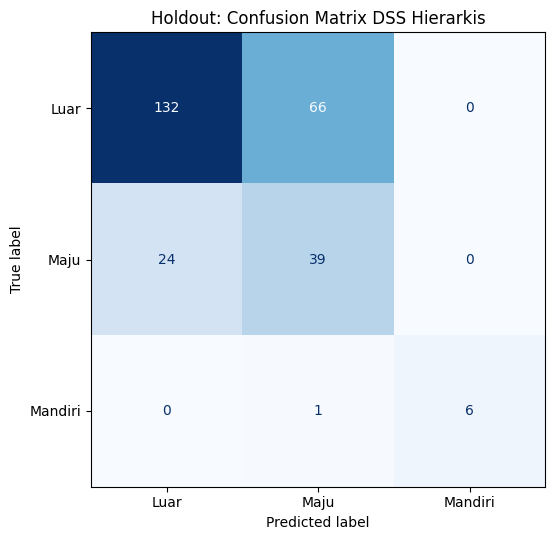

Recall Mandiri 6/7; 95% exact CI=[0.421, 0.996]


In [ ]:
def predict_hierarchy(model_a,model_b,X,threshold_a=THRESHOLD_A,threshold_b=THRESHOLD_B):
    pa = np.asarray(model_a.predict_proba(X))[:,1]
    pb = np.asarray(model_b.predict_proba(X))[:,1]
    p0,p1,p2 = 1-pa,pa*(1-pb),pa*pb
    pred = np.where(pa<threshold_a,0,np.where(pb<threshold_b,1,2))
    prob_3 = np.column_stack([p0,p1,p2])
    assert np.allclose(prob_3.sum(axis=1),1.0,atol=1e-9)
    return pred,prob_3,pa,pb

def binary_metrics(y_true,p_pos,thresh,prefix):
    y_pred = (p_pos>=thresh).astype(int)
    return {'tahap':prefix,'threshold':thresh,'n_test':int(len(y_true)),
            'positif_test':int(y_true.sum()), 'accuracy':accuracy_score(y_true,y_pred),
            'balanced_accuracy':balanced_accuracy_score(y_true,y_pred),
            'precision':precision_score(y_true,y_pred,zero_division=0),
            'recall':recall_score(y_true,y_pred,zero_division=0),
            'f1':f1_score(y_true,y_pred,zero_division=0),
            'roc_auc':roc_auc_score(y_true,p_pos),'pr_auc':average_precision_score(y_true,p_pos),
            'brier':brier_score_loss(y_true,p_pos)}

pred_test, p_test, pa_test, pb_test = predict_hierarchy(model_A,model_B,X_test)
pb_test_cond = model_B.predict_proba(X_B_test)[:,1]
pa_test_binary = model_A.predict_proba(X_test)[:,1]
metrics_AB = pd.DataFrame([
    binary_metrics(y_A_test,pa_test_binary,THRESHOLD_A,'A: Maju/Mandiri vs luar'),
    binary_metrics(y_B_test,pb_test_cond,THRESHOLD_B,'B: Mandiri vs Maju')
])
metrics_AB.to_csv(OUT_DIR/'06_evaluasi_holdout_tahap_A_B.csv',index=False,encoding='utf-8-sig')
display(metrics_AB.round(4))

y_true_test = test['label_3kelas'].astype(int).to_numpy()
labels3 = [0,1,2]
cm = confusion_matrix(y_true_test,pred_test,labels=labels3)
metrics_3 = {
    'accuracy':float(accuracy_score(y_true_test,pred_test)),
    'balanced_accuracy':float(balanced_accuracy_score(y_true_test,pred_test)),
    'macro_f1':float(f1_score(y_true_test,pred_test,average='macro',zero_division=0)),
    'weighted_f1':float(f1_score(y_true_test,pred_test,average='weighted',zero_division=0)),
    'mandiri_precision':float(precision_score(y_true_test,pred_test,labels=[2],average='macro',zero_division=0)),
    'mandiri_recall':float(recall_score(y_true_test,pred_test,labels=[2],average='macro',zero_division=0)),
    'mandiri_f1':float(f1_score(y_true_test,pred_test,labels=[2],average='macro',zero_division=0)),
    'n_test_mandiri':int((y_true_test==2).sum())
}
display(pd.DataFrame([metrics_3]).round(4))
print(classification_report(y_true_test,pred_test,labels=labels3,target_names=[LABEL_NAMES[k] for k in labels3],zero_division=0))
pd.DataFrame([metrics_3]).to_csv(OUT_DIR/'06_evaluasi_holdout_hierarkis.csv',index=False,encoding='utf-8-sig')
pd.DataFrame(cm,index=[f'aktual_{i}' for i in labels3],columns=[f'pred_{i}' for i in labels3]).to_csv(
    OUT_DIR/'06_confusion_matrix_counts.csv',encoding='utf-8-sig')

fig,ax=plt.subplots(figsize=(6.5,5.5))
ConfusionMatrixDisplay(cm,display_labels=['Luar','Maju','Mandiri']).plot(ax=ax,cmap='Blues',values_format='d',colorbar=False)
ax.set_title('Holdout: Confusion Matrix DSS Hierarkis')
fig.tight_layout();fig.savefig(OUT_DIR/'06_confusion_matrix.png',dpi=220,bbox_inches='tight');plt.show()

# Interval recall Mandiri binomial exact (Clopper-Pearson), bukan interval akurasi umum.
n_mandiri = int((y_true_test==2).sum())
tp_mandiri = int(((y_true_test==2)&(pred_test==2)).sum())
ci_lower = 0.0 if tp_mandiri==0 else beta.ppf(0.025,tp_mandiri,n_mandiri-tp_mandiri+1)
ci_upper = 1.0 if tp_mandiri==n_mandiri else beta.ppf(0.975,tp_mandiri+1,n_mandiri-tp_mandiri)
print(f'Recall Mandiri {tp_mandiri}/{n_mandiri}; 95% exact CI=[{ci_lower:.3f}, {ci_upper:.3f}]')

holdout_predictions = test[['matching_key','Desa Wisata','Kabupaten','label_3kelas']].copy()
holdout_predictions['prediksi_label'] = pred_test
holdout_predictions['p_benchmark_tingkat_lanjut'] = pa_test
holdout_predictions['p_mandiri_kondisional'] = pb_test
holdout_predictions['p_mandiri_gabungan'] = p_test[:,2]
holdout_predictions.to_csv(OUT_DIR/'06_prediksi_holdout.csv',index=False,encoding='utf-8-sig')

## Tahap 8 — Model final untuk DSS dan *readiness scoring* (seluruh 1.336 desa)

Setelah menyimpan evaluasi holdout, kedua model terpilih **dilatih ulang pada seluruh data yang relevan**. Skor dan klasifikasi di tahap ini bersifat **deployment/in-sample**, bukan estimasi generalisasi. Level readiness menggunakan batas **heuristik 0–20–40–60–80–100** untuk prioritas eksploratif; batas tersebut bukan kategori resmi JADESTA dan memerlukan uji sensitivitas/validasi pakar.

In [ ]:
model_A_full = get_estimator(BEST_A).fit(X_ALL,(y_all>=1).astype(int))
subset_B_full = df[df['label_3kelas'].isin([1,2])]
X_B_full = subset_B_full[NUM_COLS+[TEXT_COL]]
y_B_full = (subset_B_full['label_3kelas']==2).astype(int)
model_B_full = get_estimator(BEST_B).fit(X_B_full,y_B_full)

pred_all,p_all,pa_all,pb_all = predict_hierarchy(model_A_full,model_B_full,X_ALL)
result = df[['matching_key','Desa Wisata','Kabupaten','status_benchmark','label_3kelas','status_terverifikasi_JADESTA']+NUM_COLS].copy()
result['prediksi_kelas_model'] = pred_all
result['score_tingkat_lanjut_0_100'] = (pa_all*100).round(4)
result['score_menuju_mandiri_0_100'] = (p_all[:,2]*100).round(4)
result['p_mandiri_kondisional'] = pb_all.round(6)
result['tingkat_kesiapan_eksploratif'] = pd.cut(
    result['score_menuju_mandiri_0_100'],bins=[-0.001,20,40,60,80,100.00001],
    labels=['Low','Emerging Potential','Moderate Potential','High','Very High']).astype(str)
result['catatan_label'] = 'Benchmark sementara; belum verifikasi status resmi JADESTA'

result.to_csv(OUT_DIR/'07_DSS_SCORES_1336_DESA.csv',index=False,encoding='utf-8-sig')
print('Distribusi tingkat kesiapan eksploratif:')
display(result['tingkat_kesiapan_eksploratif'].value_counts().to_frame('desa'))
print('Top di luar benchmark berdasarkan score menuju Mandiri:')
display(result[result['label_3kelas']==0].sort_values('score_menuju_mandiri_0_100',ascending=False)[
    ['Desa Wisata','Kabupaten','score_tingkat_lanjut_0_100','score_menuju_mandiri_0_100','tingkat_kesiapan_eksploratif']].head(15))

Distribusi tingkat kesiapan eksploratif:


,desa
tingkat_kesiapan_eksploratif,
Low,1302
High,16
Very High,9
Moderate Potential,8
Emerging Potential,1


Top di luar benchmark berdasarkan score menuju Mandiri:


,Desa Wisata,Kabupaten,score_tingkat_lanjut_0_100,score_menuju_mandiri_0_100,tingkat_kesiapan_eksploratif
40,Desa Wisata Ekang,Kabupaten Bintan,75.6602,15.1380,Low
522,Desa Wisata Tepus,Kabupaten Gunungkidul,67.4528,13.0059,Low
211,Desa Wisata Kampoeng Jelok,Kabupaten Gunungkidul,54.3695,11.8328,Low
461,Desa Wisata Gampong Lampulo,Kota Banda Aceh,59.2083,11.1791,Low
186,Desa Wisata Dewi Mukti,Kabupaten Gresik,72.4662,11.0575,Low
531,Desa Wisata Kampung Lali Gadget,Kabupaten Sidoarjo,63.4745,10.3511,Low
517,Desa Wisata Embung Banyu Lumut,Kabupaten Trenggalek,53.2315,10.1844,Low
844,Desa Wisata ROTAN TRANGSAN,Kabupaten Sukoharjo,61.7202,10.1377,Low
261,Desa Wisata Kalakijo ( KAMPUNG INGKUNG ),Kabupaten Bantul,62.7471,9.5582,Low
320,Desa Wisata Kampung Eduwisata Bhinneka,Kota Jakarta Pusat,66.8439,9.4605,Low


## Tahap 9 — Benchmark-gap recommendation (Maju dan Mandiri terpisah)

Untuk desa **di luar benchmark**, kesenjangan dihitung terhadap median indikator **Maju**. Untuk desa **Maju**, terhadap median **Mandiri**. Status **Mandiri** menjadi kelompok referensi, bukan sasaran rekomendasi percepatan mandiri. Fokus rekomendasi pada atribut tindakan yang didukung data profil (fasilitas, atraksi, produk, kanal digital). Kesenjangan adalah **kesenjangan dokumentasi yang teramati** dan **bukan bukti bahwa fasilitas fisik tidak ada**.

In [ ]:
ACTIONABLE = {
    'num_facilities': 'Verifikasi dan lengkapi pencatatan fasilitas layanan dasar, akses, sanitasi, dan sarana wisata.',
    'num_attractions': 'Inventarisasi, dokumentasikan, dan tingkatkan kualitas atraksi yang bisa dikunjungi.',
    'num_homestay': 'Audit ketersediaan serta mutu akomodasi/homestay; lengkapi informasi bila sudah tersedia.',
    'num_tour_packages': 'Kembangkan dan dokumentasikan paket wisata dengan informasi layanan yang jelas.',
    'num_souvenirs': 'Inventarisasi produk UMKM/suvenir lokal dan tampilkan informasi produknya.',
    'has_instagram': 'Periksa keterkinian akun Instagram resmi destinasi dan lengkapi bila belum tersedia.',
    'has_facebook': 'Lengkapi informasi akun Facebook resmi apabila relevan dengan pengunjung sasaran.',
    'has_website': 'Periksa dan lengkapi situs resmi destinasi dengan informasi layanan yang terkini.'
}
benchmark_medians = df.groupby('label_3kelas')[list(ACTIONABLE)].median().T
benchmark_medians.columns = [LABEL_NAMES.get(c,c) for c in benchmark_medians.columns]
benchmark_medians.to_csv(OUT_DIR/'08_median_benchmark.csv',encoding='utf-8-sig')
display(benchmark_medians)

recs = []
for i,row in result.iterrows():
    status = int(row['label_3kelas'])
    if status == 2:
        continue
    target_class = 1 if status == 0 else 2
    target_name = LABEL_NAMES[target_class]
    benchmark = df.loc[df['label_3kelas']==target_class,list(ACTIONABLE)].median()
    gaps = []
    for feature,action in ACTIONABLE.items():
        target = float(benchmark[feature]); current = float(row[feature])
        if target <= 0:
            continue  # Tidak masuk akal merekomendasikan menaikkan fitur dengan median benchmark 0
        gap = max(0,target-current)
        if gap <= 0:
            continue
        gap_normalized = gap/max(target,1.0)
        gaps.append((gap_normalized,gap,feature,action,current,target))
    for priority,item in enumerate(sorted(gaps,reverse=True)[:3],start=1):
        normalized,gap,feature,action,current,target = item
        recs.append({'matching_key':row['matching_key'],'Desa Wisata':row['Desa Wisata'],
                     'Kabupaten':row['Kabupaten'],'status_asal':row['status_benchmark'],
                     'tujuan_benchmark':target_name,'score_menuju_mandiri_0_100':row['score_menuju_mandiri_0_100'],
                     'prioritas':priority,'fitur':feature,'nilai_teramati':current,
                     'median_benchmark':target,'gap':gap,'gap_ternormalisasi':normalized,
                     'rekomendasi_indikatif':action,
                     'peringatan':'Wajib validasi manual/lapangan; status benchmark belum terverifikasi'})
recs_df = pd.DataFrame(recs)
recs_df.to_csv(OUT_DIR/'08_rekomendasi_top3_per_desa.csv',index=False,encoding='utf-8-sig')
priority_outside = result[result['label_3kelas']==0].sort_values('score_menuju_mandiri_0_100',ascending=False)
priority_outside.to_csv(OUT_DIR/'08_prioritas_desa_di_luar_benchmark.csv',index=False,encoding='utf-8-sig')
print('Jumlah rekomendasi spesifik:',len(recs_df))
display(recs_df.head(12))

,Di Luar Benchmark,Maju,Mandiri
num_facilities,7.0,10.0,10.0
num_attractions,2.0,5.0,4.0
num_homestay,0.0,2.0,0.0
num_tour_packages,1.0,2.0,1.0
num_souvenirs,0.0,2.0,0.5
has_instagram,1.0,1.0,1.0
has_facebook,1.0,1.0,1.0
has_website,0.0,1.0,1.0


Jumlah rekomendasi spesifik: 3100


,matching_key,Desa Wisata,Kabupaten,status_asal,tujuan_benchmark,score_menuju_mandiri_0_100,prioritas,fitur,nilai_teramati,median_benchmark,gap,gap_ternormalisasi,rekomendasi_indikatif,peringatan
0,pagak | banjarnegara,Desa Wisata Pagak,Kabupaten Banjarnegara,Di Luar Benchmark,Maju,5.9355,1,num_souvenirs,0.0,2.0,2.0,1.0,Inventarisasi produk UMKM/suvenir lokal dan ta...,Wajib validasi manual/lapangan; status benchma...
1,pagak | banjarnegara,Desa Wisata Pagak,Kabupaten Banjarnegara,Di Luar Benchmark,Maju,5.9355,2,num_homestay,0.0,2.0,2.0,1.0,Audit ketersediaan serta mutu akomodasi/homest...,Wajib validasi manual/lapangan; status benchma...
2,pagak | banjarnegara,Desa Wisata Pagak,Kabupaten Banjarnegara,Di Luar Benchmark,Maju,5.9355,3,num_attractions,1.0,5.0,4.0,0.8,"Inventarisasi, dokumentasikan, dan tingkatkan ...",Wajib validasi manual/lapangan; status benchma...
3,makmur jaya | bangli,Desa Wisata Makmur Jaya,Kabupaten Bangli,Di Luar Benchmark,Maju,1.0858,1,num_facilities,0.0,10.0,10.0,1.0,Verifikasi dan lengkapi pencatatan fasilitas l...,Wajib validasi manual/lapangan; status benchma...
4,makmur jaya | bangli,Desa Wisata Makmur Jaya,Kabupaten Bangli,Di Luar Benchmark,Maju,1.0858,2,num_attractions,0.0,5.0,5.0,1.0,"Inventarisasi, dokumentasikan, dan tingkatkan ...",Wajib validasi manual/lapangan; status benchma...
5,makmur jaya | bangli,Desa Wisata Makmur Jaya,Kabupaten Bangli,Di Luar Benchmark,Maju,1.0858,3,num_tour_packages,0.0,2.0,2.0,1.0,Kembangkan dan dokumentasikan paket wisata den...,Wajib validasi manual/lapangan; status benchma...
6,panundaan | bandung,Desa Wisata Panundaan,Kabupaten Bandung,Di Luar Benchmark,Maju,0.6838,1,num_attractions,0.0,5.0,5.0,1.0,"Inventarisasi, dokumentasikan, dan tingkatkan ...",Wajib validasi manual/lapangan; status benchma...
7,panundaan | bandung,Desa Wisata Panundaan,Kabupaten Bandung,Di Luar Benchmark,Maju,0.6838,2,num_tour_packages,0.0,2.0,2.0,1.0,Kembangkan dan dokumentasikan paket wisata den...,Wajib validasi manual/lapangan; status benchma...
8,panundaan | bandung,Desa Wisata Panundaan,Kabupaten Bandung,Di Luar Benchmark,Maju,0.6838,3,num_souvenirs,0.0,2.0,2.0,1.0,Inventarisasi produk UMKM/suvenir lokal dan ta...,Wajib validasi manual/lapangan; status benchma...
9,suak gual | belitung,Desa Wisata Suak Gual,Kabupaten Belitung,Di Luar Benchmark,Maju,2.3006,1,has_website,0.0,1.0,1.0,1.0,Periksa dan lengkapi situs resmi destinasi den...,Wajib validasi manual/lapangan; status benchma...


## Tahap 10 — Permutation SHAP **langsung** pada skor akhir DSS (tanpa XGBoost)

Target SHAP adalah fungsi nyata `P_A(advanced|X) × P_B(Mandiri|advanced,X)`, yaitu kolom `score_menuju_mandiri_0_100` dibagi 100. **Dua model yang dijelaskan adalah model final yang benar-benar dilatih pada tahap deployment**, bukan XGBoost pengganti.

**Unit penjelasan:** 12 atribut terstruktur ditambah **satu blok informasi teks TF-IDF**. TF-IDF pada pengukuran ini ditukar sebagai **satu dokumen penuh**, bukan per token; plot beeswarm hanya mencakup 12 atribut numerik agar nilai ID teks tidak dianggap skala kuantitatif. Pemilihan latar/observasi secara *stratified* dicatat dan kepentingan global dirata-ratakan menggunakan **bobot prevalensi 987/315/34**, sehingga sampel kelas Mandiri yang ditambah untuk diagnosis tidak mendominasi hasil global.

Jalankan sekali untuk demonstrasi; untuk publikasi sebaiknya uji stabilitas terhadap latar SHAP, tingkatkan sampel, serta laporkan biayanya. Penjelasan SHAP bukan bukti kausalitas.

In [ ]:
try:
    import shap
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable,'-m','pip','install','shap>=0.46,<1'])
    import shap
print('SHAP version:',shap.__version__)

FEATURE_COLS = NUM_COLS+[TEXT_COL]
# Registry teks, agar masker SHAP bisa bekerja pada satu matriks numerik:
# ID teks adalah label kategorikal bagi SELURUH dokumen, bukan angka berurutan untuk diinterpretasi.
text_bank = pd.Index(X_ALL[TEXT_COL].fillna('').astype(str).unique())
text_id = {s:i for i,s in enumerate(text_bank)}

def to_shap_numeric(Xdf):
    z = Xdf[FEATURE_COLS].copy()
    z[TEXT_COL] = z[TEXT_COL].map(text_id)
    if z.isna().any().any():
        raise ValueError('Ada teks di luar bank atau fitur numerik kosong.')
    return z.astype(float)

def final_score_from_encoded(z):
    z = np.atleast_2d(np.asarray(z,dtype=float))
    raw = pd.DataFrame(z,columns=FEATURE_COLS)
    ids = np.rint(raw[TEXT_COL].to_numpy()).astype(int)
    if (ids<0).any() or (ids>=len(text_bank)).any():
        raise ValueError('ID teks di luar daftar yang valid.')
    raw[TEXT_COL] = text_bank.take(ids).astype(str)
    a = model_A_full.predict_proba(raw[FEATURE_COLS])[:,1]
    b = model_B_full.predict_proba(raw[FEATURE_COLS])[:,1]
    return a*b

z_all = to_shap_numeric(X_ALL)
original_p = result['score_menuju_mandiri_0_100'].to_numpy()/100
wrapper_p = final_score_from_encoded(z_all.iloc[:8].to_numpy())
assert np.allclose(wrapper_p,original_p[:8],atol=1e-5,rtol=1e-5), 'Wrapper SHAP tidak sesuai DSS'
print('PASS: probabilitas SHAP = probabilitas sistem DSS asli (selisih hanya pembulatan tampilan).')

def strat_sample_indices(per_class,seed):
    parts=[]
    for class_id,n in enumerate(per_class):
        pool=df.index[df['label_3kelas']==class_id]
        parts.extend(pd.Index(pool).to_series().sample(n=min(n,len(pool)),random_state=seed+class_id).tolist())
    return np.array(parts,dtype=int)

idx_bg = strat_sample_indices(SHAP_BG_PER_CLASS,SEED+100)
idx_exp = strat_sample_indices(SHAP_EXPLAIN_PER_CLASS,SEED+200)
z_bg = z_all.loc[idx_bg]
z_exp = z_all.loc[idx_exp]
D = len(FEATURE_COLS)
MAX_EVALS = SHAP_N_PERMUTATIONS*(2*D+1)
explainer = shap.Explainer(final_score_from_encoded,
    shap.maskers.Independent(z_bg,max_samples=len(z_bg)),algorithm='permutation',
    feature_names=FEATURE_COLS,seed=SEED)
print(f'Background={len(z_bg)}; explained={len(z_exp)}; permutations={SHAP_N_PERMUTATIONS}; max_evals={MAX_EVALS}')
explanations = explainer(z_exp,max_evals=MAX_EVALS)
reconstructed = explanations.base_values + explanations.values.sum(axis=1)
actual = final_score_from_encoded(z_exp.to_numpy())
assert np.allclose(reconstructed,actual,atol=1e-5), 'Aditivitas SHAP gagal!'
print('PASS: base value + sum(SHAP) = skor Mandiri DSS asli.')

SHAP version: 0.54.1
PASS: probabilitas SHAP = probabilitas sistem DSS asli (selisih hanya pembulatan tampilan).
Background=20; explained=27; permutations=2; max_evals=54


PermutationExplainer explainer: 28it [00:20,  1.55s/it]


PASS: base value + sum(SHAP) = skor Mandiri DSS asli.


## Tahap 11 — SHAP global, beeswarm dan penjelasan desa individu

`mean_abs_shap_population_weighted` dihitung melalui rata-rata per kelas pada sampel SHAP, kemudian dibobot sesuai prevalensi kelas pada dataset (987/1336, 315/1336, 34/1336). Dengan sampel kecil, grafik merupakan **analisis awal** dan harus diperkuat untuk publikasi.

,fitur,mean_abs_shap_population_weighted,mean_abs_shap_sample
12,TF-IDF (seluruh blok teks),0.138824,0.218280
1,num_facilities,0.011090,0.011057
10,has_website,0.007836,0.009151
0,description_length,0.007538,0.008558
7,has_instagram,0.003547,0.004823
11,has_twitter,0.002200,0.003025
3,num_homestay,0.001806,0.002059
4,num_tour_packages,0.001789,0.002890
2,num_attractions,0.001101,0.001999
5,num_souvenirs,0.000747,0.001462


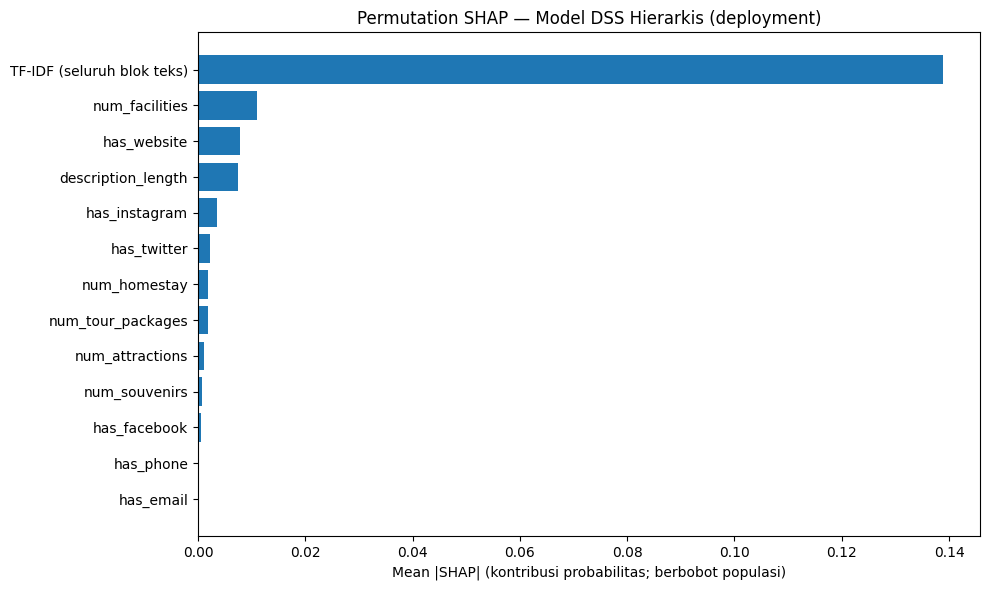

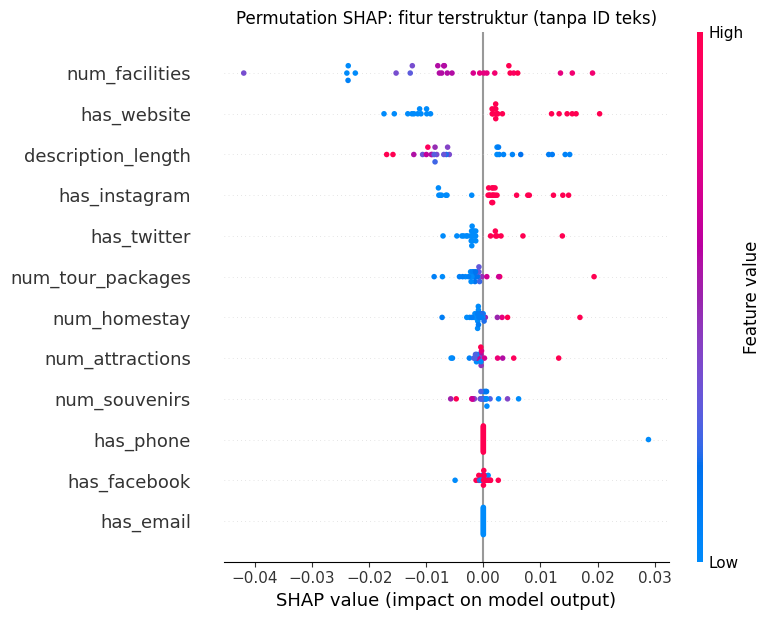

Desa contoh: Desa Wisata Ekang | score Mandiri: 15.138


,fitur,shap_contribution_probability,nilai_absolut
12,TF-IDF (seluruh blok teks),-0.029253,0.029253
10,has_website,0.005112,0.005112
0,description_length,0.004835,0.004835
7,has_instagram,0.004163,0.004163
1,num_facilities,0.003732,0.003732
11,has_twitter,-0.002656,0.002656
2,num_attractions,-0.002167,0.002167
3,num_homestay,-0.002008,0.002008
4,num_tour_packages,-0.001408,0.001408
8,has_facebook,0.000719,0.000719


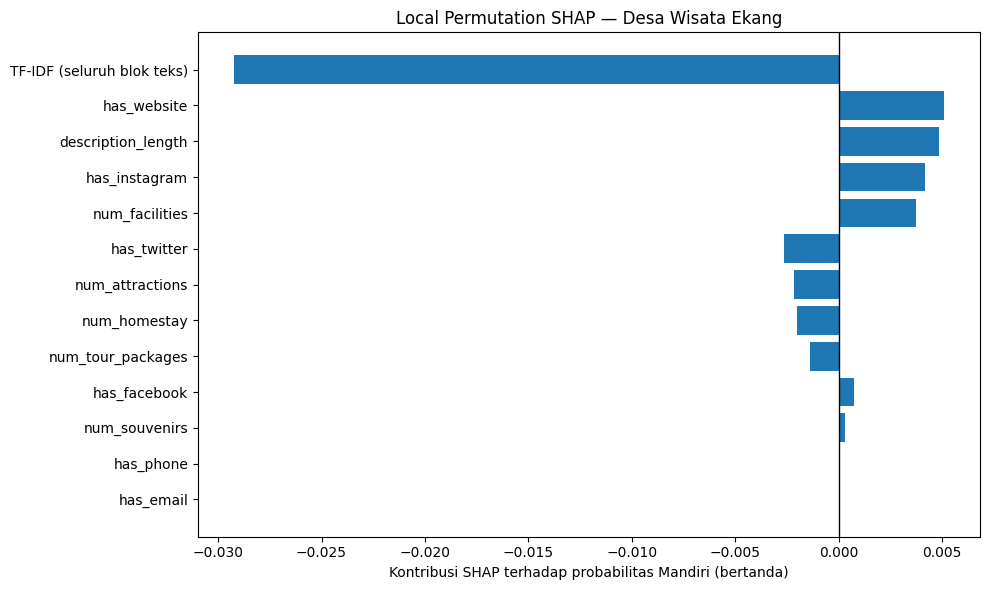

In [ ]:
strata_exp = df.loc[idx_exp,'label_3kelas'].to_numpy()
class_priors = df['label_3kelas'].value_counts(normalize=True).to_dict()
weighted_importance = np.zeros(D)
for cl in sorted(class_priors):
    class_values = np.abs(explanations.values[strata_exp==cl])
    if len(class_values)==0:
        raise RuntimeError('Ada kelas tidak terwakili dalam sampel SHAP.')
    weighted_importance += class_priors[cl]*class_values.mean(axis=0)

shap_global = pd.DataFrame({
    'fitur':NUM_COLS+['TF-IDF (seluruh blok teks)'],
    'mean_abs_shap_population_weighted':weighted_importance,
    'mean_abs_shap_sample':np.abs(explanations.values).mean(axis=0)
}).sort_values('mean_abs_shap_population_weighted',ascending=False)
shap_global.to_csv(OUT_DIR/'09_shap_global_importance.csv',index=False,encoding='utf-8-sig')
display(shap_global)

fig,ax=plt.subplots(figsize=(10,6))
ax.barh(shap_global['fitur'].iloc[::-1],shap_global['mean_abs_shap_population_weighted'].iloc[::-1])
ax.set_xlabel('Mean |SHAP| (kontribusi probabilitas; berbobot populasi)')
ax.set_title('Permutation SHAP — Model DSS Hierarkis (deployment)')
fig.tight_layout();fig.savefig(OUT_DIR/'09_shap_global.png',dpi=220,bbox_inches='tight');plt.show()

shap.plots.beeswarm(explanations[:,:len(NUM_COLS)],max_display=len(NUM_COLS),show=False)
plt.title('Permutation SHAP: fitur terstruktur (tanpa ID teks)')
plt.tight_layout();plt.savefig(OUT_DIR/'09_shap_beeswarm_numerik.png',dpi=220,bbox_inches='tight');plt.show()

# Penjelasan lokal: kandidat dengan skor terbesar dari luar benchmark
local_idx = int(priority_outside.index[0])
z_local = z_all.loc[[local_idx]]
local_xai = explainer(z_local,max_evals=MAX_EVALS)
p_local = float(final_score_from_encoded(z_local.to_numpy())[0])
assert np.isclose(float(local_xai.base_values[0]+local_xai.values[0].sum()),p_local,atol=1e-5)
local_values = pd.DataFrame({'fitur':NUM_COLS+['TF-IDF (seluruh blok teks)'],
                             'shap_contribution_probability':local_xai.values[0]})
local_values['nilai_absolut'] = local_values['shap_contribution_probability'].abs()
local_values = local_values.sort_values('nilai_absolut',ascending=False)
local_values.to_csv(OUT_DIR/'09_shap_lokal_contoh.csv',index=False,encoding='utf-8-sig')
print('Desa contoh:',result.loc[local_idx,'Desa Wisata'],'| score Mandiri:',round(p_local*100,4))
display(local_values)
fig,ax=plt.subplots(figsize=(10,6))
ax.barh(local_values['fitur'].iloc[::-1],local_values['shap_contribution_probability'].iloc[::-1])
ax.axvline(0,color='black',linewidth=1)
ax.set_xlabel('Kontribusi SHAP terhadap probabilitas Mandiri (bertanda)')
ax.set_title('Local Permutation SHAP — '+str(result.loc[local_idx,'Desa Wisata'])[:48])
fig.tight_layout();fig.savefig(OUT_DIR/'09_shap_lokal.png',dpi=220,bbox_inches='tight');plt.show()

## Tahap 12 — Ringkasan eksperimen dan ZIP output

Mencatat model A/B, threshold yang dipilih tanpa test, versi library, distribusi, metrik holdout, konfigurasi SHAP, serta peringatan label. File output otomatis dibundel menjadi ZIP untuk memudahkan pelaporan ke reviewer. Notebook `.ipynb` **tidak otomatis dimasukkan** dalam ZIP hasil Colab; simpan notebook via menu **File → Download → Download .ipynb**.

In [ ]:
experiment_manifest = {
    'data_total':int(len(df)),
    'class_counts':{str(k):int(v) for k,v in df['label_3kelas'].value_counts().sort_index().items()},
    'label_status':'BELUM terverifikasi JADESTA; label kelas 0 = di luar benchmark',
    'random_state':SEED, 'fast_mode':FAST_MODE,'cv_folds':CV_FOLDS,
    'split':'stratified 80:20; threshold/model selection from training folds only',
    'model_A':BEST_A,'model_B':BEST_B,'threshold_A':THRESHOLD_A,'threshold_B':THRESHOLD_B,
    'tfidf':{'ngram_range':[1,2],'max_features':3000,'min_df':2,'max_df':0.95},
    'structured_features':NUM_COLS,
    'score':'P(A: Maju/Mandiri|X) * P(B: Mandiri|A,X) * 100; descriptive/proxy only',
    'threshold_readiness_levels':'0-20-40-60-80-100 heuristic and unvalidated',
    'holdout_metrics':{k:float(v) for k,v in metrics_3.items()},
    'holdout_mandiri_recall_exact_95_ci':[float(ci_lower),float(ci_upper)],
    'shap':{'mode':'deployment','target':'two-stage P(Mandiri) score (same model)',
            'background_counts':list(SHAP_BG_PER_CLASS),'explained_counts':list(SHAP_EXPLAIN_PER_CLASS),
            'max_evals':int(MAX_EVALS),'feature_units':'12 structured + 1 grouped whole-text TF-IDF',
            'global_weighting':'observed class prevalence'},
    'versions':{'python':platform.python_version(),'scikit_learn':sklearn_version,'shap':shap.__version__,
                'pandas':pd.__version__,'numpy':np.__version__}
}
with open(OUT_DIR/'10_manifest_metode.json','w',encoding='utf-8') as h:
    json.dump(experiment_manifest,h,indent=2,ensure_ascii=False)

with open(OUT_DIR/'README_HASIL.txt','w',encoding='utf-8') as h:
    h.write('DSS DESA WISATA — CATATAN PENELITIAN\n'
            'Dataset 0/1/2 = di luar benchmark / Maju / Mandiri. BELUM diverifikasi JADESTA.\n'
            'Model hierarkis A: luar vs maju+mandiri; B: maju vs mandiri.\n'
            'Model dan threshold ditentukan pada training; holdout dipakai sekali untuk laporan.\n'
            'Hasil semua desa = in-sample deployment, BUKAN validasi independen.\n'
            'Skor Mandiri adalah keluaran model, bukan status resmi, probabilitas transisi, atau dampak kausal.\n'
            'SHAP dijalankan langsung ke fungsi skor akhir A*B tanpa XGBoost.\n'
            'Lihat manifest JSON untuk konfigurasi.\n')

zip_path = OUT_DIR.parent/'HASIL_DSS_1336_SHAP.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as zf:
    for path in sorted(OUT_DIR.iterdir()):
        if path.is_file():
            zf.write(path,arcname=path.name)
print('ZIP hasil:',zip_path.resolve(),'| jumlah file:',len(list(OUT_DIR.iterdir())))
try:
    from google.colab import files as colab_files
    colab_files.download(str(zip_path))
except ImportError:
    pass

ZIP hasil: /content/HASIL_DSS_1336_SHAP.zip | jumlah file: 24


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Panduan pelaporan ilmiah — khusus revisi reviewer IJITCS

- **Pertahankan konsistensi tujuan:** Dengan label 0/1/2 saat ini, sistem melakukan **benchmark-membership assessment**, bukan klasifikasi resmi empat tingkat JADESTA. Jika klasifikasi resmi seluruh desa tersedia, gunakan sebagai label yang diverifikasi dan ulangi eksperimen.
- **Tabel metode:** cantumkan distribusi 987/315/34, 80:20 split, 5-fold CV, `class_weight`, konfigurasi TF-IDF, dan dua tahap model A/B. Perhatikan bahwa **34 Mandiri** hanya menghasilkan **7 Mandiri** pada holdout.
- **Tabel hasil:** sajikan hasil CV (mean ± SD), threshold berbasis train-only OOF, evaluasi independen A/B, macro F1/confusion matrix tiga kelas, dan confidence interval recall kelas Mandiri.
- **Skor dan level kesiapan:** skor `P_A×P_B` dihitung dari model full-fit, **tidak otomatis terkalibrasi**, interval kategori bersifat heuristik. Hindari menyatakan nilai 80 berarti peluang empiris 80% menjadi Mandiri.
- **SHAP:** jelaskan direct Permutation SHAP terhadap model final, 12 fitur struktural + satu grup teks TF-IDF. Jangan mengutip pentingnya kata tertentu dari satu kelompok TF-IDF tanpa analisis token tambahan.
- **Rekomendasi:** gunakan median grup Maju/Mandiri dengan verifikasi lapangan/pakar; entri profil kosong berarti belum terdokumentasi, bukan pasti tidak tersedia.
- **Penelitian lanjutan:** verifikasi kategori JADESTA, evaluasi sensitivitas batas readiness, kalibrasi probabilitas, validasi eksternal, dan validasi pakar/instansi untuk rekomendasi.

# Audit dan penguatan Tahap A — DSS Desa Wisata (1.336 identitas)

**Tujuan:** memperkuat klasifikasi kelompok *di luar benchmark* (`0`) vs *benchmark tingkat lanjut Maju/Mandiri* (`1`), **bukan** menetapkan status resmi JADESTA.

**Disiplin evaluasi**
- Menggunakan 987 + 315 + 34 identitas unik dari 3 CSV hasil pembersihan.
- Mempertahankan **holdout 80:20 yang sama** (`random_state=42`). **Tidak mengukur ulang, mengoptimalkan, atau memilih model berdasarkan hasil holdout lama**, karena holdout sebelumnya sudah dilihat. Untuk estimasi ketidakpastian digunakan *nested/repeated CV* **khusus 1.068 data training**.
- Bandingkan Logistic Regression, Calibrated Linear SVM, dan Random Forest dengan 4 studi ablasi. Semua TF-IDF/scaler dilatih **di dalam fold**.
- Model dan threshold dipilih pada *inner folds*, lalu diuji pada *outer folds* yang independen terhadap pemilihan tersebut.
- Dilakukan audit *missingness*, *sensitivity by regency* (geographical holdout), dan *paired bootstrap* tingkat **desa** tanpa memperlakukan pengulangan CV sebagai sampel independen.

**Batasan sangat penting:** 987 desa di luar benchmark belum terbukti semuanya bukan Maju/Mandiri; seluruh kolom `status_terverifikasi_JADESTA` masih `BELUM`. Eksperimen ini mengevaluasi **keanggotaan terhadap daftar benchmark sementara**, bukan prediksi kesiapan resmi atau efek kausal. Jika label terverifikasi berbeda, eksperimen wajib diulang.

## 0. Persiapan dan input tiga CSV

Jalankan di Google Colab. Jika berkas sudah ada di `/content`, tidak perlu unggah ulang. `DSS_FAST_MODE=1` **hanya untuk debugging**, bukan angka manuskrip. Secara default mode penelitian adalah penuh.

In [ ]:
import os, sys, re, json, zipfile, warnings, random, platform
from pathlib import Path
from urllib.parse import urlparse
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn import __version__ as sklearn_version
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report, brier_score_loss)
from scipy.stats import beta

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
FAST_MODE = os.environ.get('DSS_FAST_MODE', '0') == '1'  # Default: MODE PENELITIAN
CV_FOLDS = 3 if FAST_MODE else 5
RF_TREES = 55 if FAST_MODE else 160
SHAP_BG_PER_CLASS = (3, 3, 3) if FAST_MODE else (10, 6, 4)
SHAP_EXPLAIN_PER_CLASS = (3, 2, 1) if FAST_MODE else (12, 9, 6)
SHAP_N_PERMUTATIONS = 1 if FAST_MODE else 2

OUT_DIR = Path('/content/hasil_robustness_tahap_A' if Path('/content').exists() else 'hasil_robustness_tahap_A')
OUT_DIR.mkdir(parents=True, exist_ok=True)
FILES = {
    0: 'DESA_DI_LUAR_BENCHMARK_987.csv',
    1: 'DESA_MAJU_315.csv',
    2: 'DESA_MANDIRI_34.csv',
}
LABEL_NAMES = {0: 'Di Luar Benchmark', 1: 'Maju', 2: 'Mandiri'}
print('FAST_MODE:', FAST_MODE, '| CV_FOLDS:', CV_FOLDS, '| output:', OUT_DIR.resolve())
print('scikit-learn:', sklearn_version)

FAST_MODE: False | CV_FOLDS: 5 | output: /content/hasil_robustness_tahap_A
scikit-learn: 1.6.1


In [ ]:
import time, itertools, joblib, hashlib
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import precision_recall_curve, RocCurveDisplay, PrecisionRecallDisplay
from sklearn.dummy import DummyClassifier

FAST_MODE = os.environ.get('DSS_FAST_MODE','0') == '1'
SCREEN_REPEATS = 1 if FAST_MODE else 3
OUTER_REPEATS = 1 if FAST_MODE else 2
OUTER_FOLDS = 3 if FAST_MODE else 5
INNER_FOLDS = 2 if FAST_MODE else 3
RF_TREES_A = 35 if FAST_MODE else 140
BOOTSTRAP_N = 150 if FAST_MODE else 1500
# PILIHAN: seluruh 12 kandidat pada CV nested. Jangan mengubah berdasarkan hasil holdout.
print('Konfigurasi:', {'FAST_MODE':FAST_MODE,'screen_repeats':SCREEN_REPEATS,'outer':(OUTER_FOLDS,OUTER_REPEATS),'inner':INNER_FOLDS,'bootstrap':BOOTSTRAP_N})

Konfigurasi: {'FAST_MODE': False, 'screen_repeats': 3, 'outer': (5, 2), 'inner': 3, 'bootstrap': 1500}


## 1. Pembacaan dan validasi data (tanpa merancang ulang label)

Normalisasi fitur mengikuti notebook DSS versi sebelumnya, supaya perbandingan tetap adil. Identitas dan sumber label **tidak dipakai sebagai prediktor**.

In [ ]:
missing_files = [name for name in FILES.values() if not Path(name).exists()]
if missing_files:
    try:
        from google.colab import files as colab_files
        print('Silakan unggah semua CSV berikut:', missing_files)
        colab_files.upload()
    except ImportError as exc:
        raise FileNotFoundError('Salin file berikut ke folder kerja: ' + ', '.join(missing_files)) from exc

frames = []
for label, filename in FILES.items():
    if not Path(filename).exists():
        raise FileNotFoundError('CSV tidak tersedia: ' + filename)
    part = pd.read_csv(filename, dtype=str, keep_default_na=False, encoding='utf-8-sig')
    part['label_3kelas'] = label
    part['status_benchmark'] = LABEL_NAMES[label]
    part['file_sumber_label'] = filename
    frames.append(part)
    print(filename, '->', len(part), 'baris')

df_raw = pd.concat(frames, ignore_index=True)
assert df_raw.shape[0] == 1336, f'Jumlah data berubah: {len(df_raw)}. Audit sumber sebelum melanjutkan.'
assert df_raw['label_3kelas'].value_counts().to_dict() == {0: 987, 1: 315, 2: 34}
required_columns = ['Desa Wisata','Kabupaten','Deskripsi','Fasilitas','Atraksi','homestay',
                    'pakert wisata','sovenir','HP','IG','FB','Email','Website','Twitter','matching_key']
missing_cols = sorted(set(required_columns) - set(df_raw.columns))
assert not missing_cols, f'Kolom hilang: {missing_cols}'
assert (df_raw['matching_key'].astype(str).str.strip() != '').all(), 'Ada matching_key kosong'
assert not df_raw['matching_key'].duplicated().any(), 'Identitas desa terduplikasi. Periksa sumber!'
assert (df_raw['status_terverifikasi_JADESTA'].str.upper() == 'BELUM').all(), 'Status verifikasi berubah; periksa ulang metodologi.'

summary = df_raw.groupby(['label_3kelas','status_benchmark']).size().reset_index(name='jumlah')
summary['persentase'] = (summary['jumlah'] / len(df_raw) * 100).round(2)
display(summary)
summary.to_csv(OUT_DIR/'01_distribusi_label.csv', index=False, encoding='utf-8-sig')
print('Total identitas unik:', df_raw['matching_key'].nunique())
print('PENTING: Seluruh label adalah benchmark sementara, bukan verifikasi JADESTA.')

DESA_DI_LUAR_BENCHMARK_987.csv -> 987 baris
DESA_MAJU_315.csv -> 315 baris
DESA_MANDIRI_34.csv -> 34 baris


,label_3kelas,status_benchmark,jumlah,persentase
0,0,Di Luar Benchmark,987,73.88
1,1,Maju,315,23.58
2,2,Mandiri,34,2.54


Total identitas unik: 1336
PENTING: Seluruh label adalah benchmark sementara, bukan verifikasi JADESTA.


## 2. Rekonstruksi 12 fitur terstruktur dan blok TF-IDF

- Produk/fasilitas/akomodasi: enam fitur numerik.
- Kanal digital: enam fitur, termasuk telepon dan email.
- Seluruh teks destinasi digabung sebagai satu kolom mentah untuk TF-IDF; nama desa/kabupaten tidak dimasukkan.
- Kolom `status_benchmark`/`matching_key`/`label_3kelas` hanya dipakai untuk pencocokan/evaluasi, **tidak masuk fitur**.

In [ ]:
EMPTY_VALUES = {'', '-', '--', '---', 'nan', 'none', 'null', 'n/a', 'na', 'tidak ada', 'belum ada', 'tdk ada'}
PSEUDO = {
    'Fasilitas': {'fasilitas', 'belum ada fasilitas untuk ditampilkan', 'belum tersedia'},
    'Atraksi': {'atraksi wisata', 'atraksi', 'belum ada atraksi untuk ditampilkan'},
    'homestay': {'kamar homestay', 'homestay', 'belum ada homestay untuk ditampilkan'},
    'pakert wisata': {'paket wisata', 'belum ada paket wisata untuk ditampilkan'},
    'sovenir': {'suvenir', 'souvenir', 'belum ada suvenir untuk ditampilkan'},
}

def clean_text(value):
    if pd.isna(value):
        return ''
    text = str(value).strip()
    if text.lower() in EMPTY_VALUES:
        return ''
    # Hapus ekspresi penghargaan/ranking yang berpotensi membocorkan label
    text = re.sub(r'\b\d+\s*besar\s*adwi\s*(?:20\d{2})?\b', ' ', text, flags=re.I)
    text = re.sub(r'\badwi\s*(?:20\d{2})?\b', ' ', text, flags=re.I)
    text = re.sub(r'\b(?:status|klasifikasi|kategori)\s+(?:desa\s+wisata\s+)?(?:mandiri|maju|rintisan|berkembang)\b', ' ', text, flags=re.I)
    return re.sub(r'\s+', ' ', text).strip()

def count_documented_items(value, column):
    text = clean_text(value)
    if not text or 'belum ada' in text.lower() or 'belum tersedia' in text.lower():
        return 0
    # Harga dalam format Rp 150,000 tidak boleh dihitung sebagai 2 entri
    text = re.sub(r'(?<=\d),(?=\d{3}(?:\D|$))', '', text)
    parts = re.split(r'[,;\n\r|]+', text)
    items = []
    for item in parts:
        item = item.strip(' .-_')
        if not item or item.lower() in PSEUDO[column]:
            continue
        for heading in PSEUDO[column]:
            if item.lower().startswith(heading + ' ') and len(item) > len(heading) + 2:
                item = item[len(heading):].strip()
        if item and item.lower() not in PSEUDO[column]:
            items.append(item)
    return len(items)

def valid_channel(value, channel):
    s = clean_text(value)
    if not s:
        return 0
    if channel == 'HP':
        return int(len(re.sub(r'\D', '', s)) >= 8)
    if channel == 'Email':
        return int(bool(re.search(r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b', s)))
    url = s if re.match(r'^https?://', s, flags=re.I) else 'https://' + s
    parsed = urlparse(url)
    host = parsed.netloc.lower().removeprefix('www.')
    slug = parsed.path.strip('/').lower()
    if channel == 'IG':
        return int(host in ('instagram.com','instagr.am') and slug not in ('','p','reel','stories','explore','jadestaofficial'))
    if channel == 'FB':
        return int(host in ('facebook.com','m.facebook.com','fb.com') and slug not in ('','jadestaofficial'))
    if channel == 'Twitter':
        return int(host in ('twitter.com','x.com') and slug not in ('','jadestaofficial','home','search'))
    if channel == 'Website':
        banned = ('facebook.com','instagram.com','twitter.com','x.com','wa.me','whatsapp.com',
                  'wa.link','linktr.ee','jadesta.kemenpar.go.id','jadesta.kemenparekraf.go.id')
        return int(bool(host and '.' in host and not any(host == d or host.endswith('.'+d) for d in banned)))
    return 0

NUM_COLS = ['description_length','num_facilities','num_attractions','num_homestay',
            'num_tour_packages','num_souvenirs','has_phone','has_instagram',
            'has_facebook','has_email','has_website','has_twitter']
TEXT_COL = 'combined_text_model'
TEXT_SOURCE_COLS = ['Deskripsi','Fasilitas','Atraksi','homestay','pakert wisata','sovenir']

df = df_raw.copy()
for col in required_columns:
    df[col] = df[col].fillna('').astype(str)
for col in TEXT_SOURCE_COLS:
    df['clean_' + col] = df[col].map(clean_text)

df['description_length'] = df['clean_Deskripsi'].map(lambda x: len(re.findall(r'\b\w+\b', x)))
for col, feature in [('Fasilitas','num_facilities'),('Atraksi','num_attractions'),
                     ('homestay','num_homestay'),('pakert wisata','num_tour_packages'),('sovenir','num_souvenirs')]:
    df[feature] = df[col].map(lambda x: count_documented_items(x, col))
for col, feature in [('HP','has_phone'),('IG','has_instagram'),('FB','has_facebook'),
                     ('Email','has_email'),('Website','has_website'),('Twitter','has_twitter')]:
    df[feature] = df[col].map(lambda x: valid_channel(x, col))

df[TEXT_COL] = df[['clean_' + col for col in TEXT_SOURCE_COLS]].agg(' '.join,axis=1).str.replace(r'\s+',' ',regex=True).str.strip()
for col in NUM_COLS:
    df[col] = pd.to_numeric(df[col], errors='raise').astype(float)
df['digital_presence_score'] = df[['has_instagram','has_facebook','has_email','has_website','has_twitter']].sum(axis=1)
df['product_readiness_score'] = df[['num_attractions','num_tour_packages','num_souvenirs']].sum(axis=1)
df['infrastructure_readiness_score'] = df[['num_facilities','num_homestay']].sum(axis=1)
assert df[NUM_COLS+[TEXT_COL]].notna().all().all()
assert (df[NUM_COLS].to_numpy() >= 0).all()

X_ALL = df[NUM_COLS+[TEXT_COL]].copy()
y_all = df['label_3kelas'].astype(int)
print('Matriks mentah prediktor:',X_ALL.shape,'| 12 numerik + 1 blok teks')
display(df.groupby('status_benchmark')[NUM_COLS].agg(['mean','median']).round(2).iloc[:,:12])
df[['matching_key','label_3kelas']+NUM_COLS+['digital_presence_score','product_readiness_score','infrastructure_readiness_score']].to_csv(
    OUT_DIR/'02_fitur_terstruktur_audit.csv',index=False,encoding='utf-8-sig')

Matriks mentah prediktor: (1336, 13) | 12 numerik + 1 blok teks


description_length        num_facilities         \
                                mean median           mean median   
status_benchmark                                                    
Di Luar Benchmark             186.45   89.0           6.57    7.0   
Maju                          215.37  135.0           8.82   10.0   
Mandiri                        65.68   51.0           9.71   10.0   

                  num_attractions        num_homestay         \
                             mean median         mean median   
status_benchmark                                               
Di Luar Benchmark            4.25    2.0         1.51    0.0   
Maju                         6.91    5.0         3.38    2.0   
Mandiri                      6.24    4.0         0.65    0.0   

                  num_tour_packages        num_souvenirs         
                               mean median          mean median  
status_benchmark                                                 
Di Luar Benchmark              2.21    1.0          1.76    0.0  
Maju                           3.77    2.0          2.78    2.0  
Mandiri                        3.71    1.0          1.97    0.5

## 3. Pembekuan split holdout dan audit identitas

Jika file ZIP hasil lama tersedia, bandingkan `matching_key` dari pembagian train/test. Notebook ini **tidak melatih/mengevaluasi pada holdout**; hasil 20% hanya dipakai untuk mengaudit konsistensi pembagian.

In [ ]:
train_idx, test_idx = train_test_split(df.index.to_numpy(), test_size=0.20, stratify=y_all, random_state=SEED)
train_idx, test_idx = np.sort(train_idx), np.sort(test_idx)
assert len(set(train_idx) & set(test_idx)) == 0
train = df.loc[train_idx].copy()
test = df.loc[test_idx].copy()
X_train = train[NUM_COLS + [TEXT_COL]].copy()
X_test = test[NUM_COLS + [TEXT_COL]].copy()
y_A_train = (train['label_3kelas'] >= 1).astype(int)
y_A_test = (test['label_3kelas'] >= 1).astype(int)
train_B = train[train['label_3kelas'].isin([1,2])].copy()
test_B = test[test['label_3kelas'].isin([1,2])].copy()
X_B_train = train_B[NUM_COLS + [TEXT_COL]].copy()
X_B_test = test_B[NUM_COLS + [TEXT_COL]].copy()
y_B_train = (train_B['label_3kelas'] == 2).astype(int)
y_B_test = (test_B['label_3kelas'] == 2).astype(int)

split_table = pd.concat([
    train['label_3kelas'].value_counts().sort_index().rename('train_80'),
    test['label_3kelas'].value_counts().sort_index().rename('test_20')], axis=1).fillna(0).astype(int)
split_table['total'] = split_table.sum(axis=1)
split_table['kelas'] = split_table.index.map(LABEL_NAMES)
display(split_table)
split_table.to_csv(OUT_DIR/'03_split_train_test.csv',encoding='utf-8-sig')
train[['matching_key','Desa Wisata','Kabupaten','label_3kelas']].to_csv(OUT_DIR/'03_train_ids.csv',index=False,encoding='utf-8-sig')
test[['matching_key','Desa Wisata','Kabupaten','label_3kelas']].to_csv(OUT_DIR/'03_test_ids.csv',index=False,encoding='utf-8-sig')

,train_80,test_20,total,kelas
label_3kelas,,,,
0,789,198,987,Di Luar Benchmark
1,252,63,315,Maju
2,27,7,34,Mandiri


In [ ]:
# Jika ZIP hasil eksperimen sebelumnya diunggah, pastikan pembagian tidak berubah.
prior_zip = Path('HASIL_DSS_1336_SHAP.zip')
if prior_zip.exists():
    with zipfile.ZipFile(prior_zip) as z:
        old_train=pd.read_csv(z.open('03_train_ids.csv'),dtype=str)['matching_key'].tolist()
        old_test=pd.read_csv(z.open('03_test_ids.csv'),dtype=str)['matching_key'].tolist()
    assert set(old_train)==set(train['matching_key']), 'Split TRAIN berbeda dengan eksperimen lama.'
    assert set(old_test)==set(test['matching_key']), 'Split TEST berbeda dengan eksperimen lama.'
    print('PASS: train/test identik dengan eksperimen DSS sebelumnya.')
else:
    print('ZIP lama opsional tidak tersedia. Split dihitung ulang deterministik dengan seed 42.')
assert len(train)==1068 and len(test)==268
assert not set(train['matching_key']) & set(test['matching_key'])
assert train['matching_key'].is_unique and test['matching_key'].is_unique
assert int(y_A_train.sum())==279 and int(y_A_test.sum())==70
print('TRAIN',len(train),'(positif proxy',int(y_A_train.sum()),') | HOLDOUT TERKUNCI',len(test),'(positif proxy',int(y_A_test.sum()),')')

PASS: train/test identik dengan eksperimen DSS sebelumnya.
TRAIN 1068 (positif proxy 279 ) | HOLDOUT TERKUNCI 268 (positif proxy 70 )


## 4. Audit kualitas label dan data hilang

Audit difokuskan pada perbedaan proporsi pengisian informasi antar kelompok. Pola hilang yang berbeda dapat membuat model mempelajari **kebiasaan dokumentasi**, bukan kematangan destinasi.

In [ ]:
quality=[]
for target_col,flag_col in [('Deskripsi','description_length'),('Website','has_website'),('IG','has_instagram'),('FB','has_facebook'),('Twitter','has_twitter')]:
    for label,g in train.groupby('label_3kelas'):
        q={'kolom':target_col,'kelas':LABEL_NAMES[int(label)],'n':len(g)}
        if target_col=='Deskripsi':q['persen_tidak_terdokumentasi']=100*(g['description_length']==0).mean()
        else:q['persen_tidak_terdokumentasi']=100*(g[flag_col]==0).mean()
        quality.append(q)
quality_df=pd.DataFrame(quality)
quality_df.to_csv(OUT_DIR/'01_audit_kelengkapan_train.csv',index=False)
display(quality_df.pivot(index='kolom',columns='kelas',values='persen_tidak_terdokumentasi').round(1))

# Periksa apakah string status eksplisit masih tersisa pada fitur teks
status_pattern = r'(?i)\b(?:kategori|klasifikasi|berstatus|status)\s+(?:desa\s+wisata\s+)?(?:mandiri|maju|berkembang|rintisan)\b'
leaks=train[train[TEXT_COL].str.contains(status_pattern,regex=True,na=False)]
print('Sisa pola status eksplisit di teks TRAIN:',len(leaks))
leaks[['matching_key','label_3kelas']].to_csv(OUT_DIR/'01_audit_kata_status.csv',index=False)

kelas,Di Luar Benchmark,Maju,Mandiri
kolom,,,
Deskripsi,26.4,20.2,3.7
FB,33.3,25.8,0.0
IG,34.9,22.6,7.4
Twitter,81.1,70.6,70.4
Website,66.9,48.0,7.4


Sisa pola status eksplisit di teks TRAIN: 0


## 5. Studi ablasi terdaftar dan tiga algoritma

Empat set fitur: **structured only**, **TF-IDF only**, **structured+TF-IDF**, dan **structured tanpa kanal digital + TF-IDF**. Seluruh pra-pemrosesan dipasang di dalam `Pipeline` agar tidak terjadi *vocabulary/data leakage*. Dalam model berbasis RF, seluruh TF-IDF juga tetap berada di pipeline.

Evaluasi memilih model berdasarkan **PR-AUC (average precision)**, sedangkan F1/BA dipakai sebagai pendamping; tidak memilih berdasarkan akurasi total.

In [ ]:
NUM_CORE = ['description_length','num_facilities','num_attractions','num_homestay','num_tour_packages','num_souvenirs']
ABLATIONS = {
 'structured_only': {'num':NUM_COLS, 'text':False},
 'tfidf_only': {'num':[], 'text':True},
 'structured_plus_tfidf': {'num':NUM_COLS, 'text':True},
 'non_digital_plus_tfidf': {'num':NUM_CORE, 'text':True},
}
MODELS_A=['Logistic Regression','Calibrated Linear SVM','Random Forest']
CANDIDATES=[(m,a) for m in MODELS_A for a in ABLATIONS]

def stageA_estimator(model_name, ablation_name):
    cfg=ABLATIONS[ablation_name]
    transformers=[]
    if cfg['num']:
        transformers.append(('numerik',StandardScaler(),cfg['num']))
    if cfg['text']:
        transformers.append(('tfidf',TfidfVectorizer(
            ngram_range=(1,2), min_df=2,max_df=0.95,max_features=3000,
            sublinear_tf=True,strip_accents=None),TEXT_COL))
    feats=ColumnTransformer(transformers,remainder='drop',sparse_threshold=0.30)
    if model_name=='Logistic Regression':
        return Pipeline([('fitur',feats),('model',LogisticRegression(
            solver='liblinear',class_weight='balanced',max_iter=2500,random_state=42))])
    if model_name=='Calibrated Linear SVM':
        base=Pipeline([('fitur',feats),('model',LinearSVC(
            dual='auto',max_iter=6000,class_weight='balanced',random_state=42))])
        return CalibratedClassifierCV(estimator=base,method='sigmoid',cv=3)
    if model_name=='Random Forest':
        return Pipeline([('fitur',feats),('model',RandomForestClassifier(
            n_estimators=RF_TREES_A,min_samples_leaf=2,class_weight='balanced_subsample',
            n_jobs=-1,random_state=42))])
    raise KeyError(model_name)

TRAIN_INPUTS=NUM_COLS+[TEXT_COL]
Xa=train[TRAIN_INPUTS].reset_index(drop=True)
ya=(train['label_3kelas'].to_numpy()>=1).astype(int)
assert len(Xa)==len(ya)==1068
assert len(CANDIDATES)==12

## 6. Repeated Stratified 5-Fold CV — perbandingan eksploratif

Hasil `repeated CV` bermanfaat melihat variasi pembagian data. **Fold dari pengulangan berbeda bukan observasi independen**, sehingga nilai simpangan bakunya tidak boleh langsung dijadikan *standard error* atau dasar uji-t antar-fold. Analisis berikutnya menggunakan nested CV untuk estimasi yang tidak memakai fold seleksi sebagai fold evaluasi.

In [ ]:
score_names={'ap':'average_precision','auc':'roc_auc','balacc':'balanced_accuracy',
             'f1':'f1','recall':'recall','precision':'precision','accuracy':'accuracy'}
screener=RepeatedStratifiedKFold(n_splits=OUTER_FOLDS,n_repeats=SCREEN_REPEATS,random_state=SEED)
screen_rows=[]
start=time.time()
for model_name,ablation_name in CANDIDATES:
    print(f'Screen {model_name:24} | {ablation_name:26}',flush=True)
    sc=cross_validate(stageA_estimator(model_name,ablation_name), Xa,ya,
                      cv=screener,scoring=score_names,n_jobs=1,error_score='raise')
    row={'model':model_name,'ablation':ablation_name,'n_folds':len(sc['test_ap'])}
    for met in score_names:
        a=sc['test_'+met]
        row[met+'_mean']=float(a.mean());row[met+'_sd_fold_deskriptif']=float(a.std(ddof=1))
    screen_rows.append(row)
screen=pd.DataFrame(screen_rows).sort_values(['ap_mean','balacc_mean'],ascending=False).reset_index(drop=True)
screen.to_csv(OUT_DIR/'02_screening_12_kombinasi.csv',index=False)
print(f'Durasi screening: {time.time()-start:.1f} detik (hanya debugging jika FAST_MODE).')
display(screen[['model','ablation','ap_mean','ap_sd_fold_deskriptif','balacc_mean','f1_mean','recall_mean']].round(4))

Screen Logistic Regression      | structured_only           
Screen Logistic Regression      | tfidf_only                
Screen Logistic Regression      | structured_plus_tfidf     
Screen Logistic Regression      | non_digital_plus_tfidf    
Screen Calibrated Linear SVM    | structured_only           
Screen Calibrated Linear SVM    | tfidf_only                


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Screen Calibrated Linear SVM    | structured_plus_tfidf     


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Screen Calibrated Linear SVM    | non_digital_plus_tfidf    


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Screen Random Forest            | structured_only           
Screen Random Forest            | tfidf_only                
Screen Random Forest            | structured_plus_tfidf     
Screen Random Forest            | non_digital_plus_tfidf    
Durasi screening: 234.5 detik (hanya debugging jika FAST_MODE).


,model,ablation,ap_mean,ap_sd_fold_deskriptif,balacc_mean,f1_mean,recall_mean
0,Logistic Regression,tfidf_only,0.5285,0.0659,0.6445,0.4773,0.4993
1,Logistic Regression,non_digital_plus_tfidf,0.5034,0.0756,0.6442,0.4782,0.5160
2,Calibrated Linear SVM,non_digital_plus_tfidf,0.4952,0.0793,0.5313,0.1306,0.0741
3,Logistic Regression,structured_plus_tfidf,0.4948,0.0778,0.6367,0.4704,0.5184
4,Calibrated Linear SVM,tfidf_only,0.4931,0.0659,0.5223,0.0919,0.0514
5,Calibrated Linear SVM,structured_plus_tfidf,0.4859,0.0802,0.5249,0.1028,0.0573
6,Random Forest,non_digital_plus_tfidf,0.4733,0.0610,0.5679,0.2728,0.1780
7,Random Forest,structured_plus_tfidf,0.4673,0.0571,0.5692,0.2773,0.1839
8,Random Forest,tfidf_only,0.4616,0.0558,0.5694,0.2737,0.1768
9,Calibrated Linear SVM,structured_only,0.4372,0.0537,0.5116,0.0659,0.0359


## 7. Nested CV — pemilihan model+ablasi+threshold di dalam data pelatihan

Untuk **setiap outer fold**: (1) pada *inner training* bandingkan seluruh 12 kandidat menurut mean AP; (2) pilih satu kandidat; (3) lakukan prediksi OOF inner untuk optimasi threshold F1; (4) latih kandidat pada seluruh outer training; (5) prediksi outer validation. Semua tahap seleksi **tidak menyentuh outer validation**.

Pengulangan outer CV mengevaluasi sensitivitas terhadap pemisahan data. Data holdout lama tetap tidak disentuh.

In [ ]:
def choose_threshold(y,p):
    grid=[]
    for th in np.round(np.arange(0.10,0.901,0.02),2):
        pr=(np.asarray(p)>=th).astype(int)
        grid.append((float(th),float(f1_score(y,pr,zero_division=0)),
                     float(balanced_accuracy_score(y,pr)),float(recall_score(y,pr,zero_division=0))))
    # Urutan deterministik: F1, BA, recall, paling dekat dari 0.5
    return max(grid,key=lambda t:(t[1],t[2],t[3],-abs(t[0]-0.5)))[0]

def metrics_row(y,p,pred):
    return {'pr_auc':float(average_precision_score(y,p)),
            'roc_auc':float(roc_auc_score(y,p)) if len(np.unique(y))==2 else np.nan,
            'balanced_accuracy':float(balanced_accuracy_score(y,pred)),
            'f1':float(f1_score(y,pred,zero_division=0)),
            'precision':float(precision_score(y,pred,zero_division=0)),
            'recall':float(recall_score(y,pred,zero_division=0)),
            'accuracy':float(accuracy_score(y,pred)),
            'brier':float(brier_score_loss(y,p))}

# Default full: outer 5 folds x 2 repeats; inner 3 folds. FAST: outer 3x1, inner 2.
all_records=[]; fold_records=[]; starts=time.time()
for rep in range(OUTER_REPEATS):
    outer=StratifiedKFold(n_splits=OUTER_FOLDS,shuffle=True,random_state=SEED+rep)
    for fold,(idx_fit,idx_eval) in enumerate(outer.split(Xa,ya),start=1):
        Xin,yin=Xa.iloc[idx_fit],ya[idx_fit]
        Xout,yout=Xa.iloc[idx_eval],ya[idx_eval]
        icv=StratifiedKFold(n_splits=INNER_FOLDS,shuffle=True,random_state=SEED+300+fold+rep*100)
        candidates_rank=[]
        for model_name,ablation_name in CANDIDATES:
            sc=cross_validate(stageA_estimator(model_name,ablation_name),Xin,yin,
                    cv=icv,scoring={'ap':'average_precision','ba':'balanced_accuracy'},
                    n_jobs=1,error_score='raise')
            candidates_rank.append((float(sc['test_ap'].mean()),float(sc['test_ba'].mean()),model_name,ablation_name))
        # Tie break deterministik berdasarkan nama
        best=sorted(candidates_rank,key=lambda x:(-x[0],-x[1],x[2],x[3]))[0]
        _,_,best_name,best_ablation=best
        chosen=stageA_estimator(best_name,best_ablation)
        p_oof=cross_val_predict(chosen,Xin,yin,cv=icv,method='predict_proba',n_jobs=1)[:,1]
        chosen_threshold=choose_threshold(yin,p_oof)
        chosen.fit(Xin,yin)
        p=chosen.predict_proba(Xout)[:,1]
        pred=(p>=chosen_threshold).astype(int)

        # Pembanding pra-spesifikasi: Logistic Regression + 12 numerik + TF-IDF,
        # threshold dipilih via OOF inner dengan data outer-training saja.
        baseline=stageA_estimator('Logistic Regression','structured_plus_tfidf')
        p_baseline_oof=cross_val_predict(baseline,Xin,yin,cv=icv,method='predict_proba',n_jobs=1)[:,1]
        th_baseline=choose_threshold(yin,p_baseline_oof)
        baseline.fit(Xin,yin)
        pb=baseline.predict_proba(Xout)[:,1]
        predb=(pb>=th_baseline).astype(int)
        fm=metrics_row(yout,p,pred)
        fb=metrics_row(yout,pb,predb)
        fold_records.append({'repeat':rep+1,'fold':fold,'selected_model':best_name,
             'selected_ablation':best_ablation,'inner_mean_ap':best[0],
             'threshold_selected':chosen_threshold,'threshold_baseline':th_baseline,
             'n_outer_test':len(idx_eval),'outer_pos':int(yout.sum()),
             **{'selected_'+k:v for k,v in fm.items()},
             **{'baseline_'+k:v for k,v in fb.items()}})
        for j,original_pos in enumerate(idx_eval):
            all_records.append({'repeat':rep+1,'fold':fold,
                'matching_key':train.iloc[original_pos]['matching_key'],
                'y':int(yout[j]),'p_selected':float(p[j]),'pred_selected':int(pred[j]),
                'p_legacy_lr':float(pb[j]),'pred_legacy_lr':int(predb[j]),
                'threshold_selected':chosen_threshold,'threshold_legacy_lr':th_baseline,
                'selected_model':best_name,'selected_ablation':best_ablation})
        print(f'Nested repeat {rep+1}/{OUTER_REPEATS}, fold {fold}/{OUTER_FOLDS}: '
              f'{best_name} + {best_ablation}, AP={fm["pr_auc"]:.3f}, F1={fm["f1"]:.3f}',flush=True)
print('Durasi nested:',round(time.time()-starts,1),'detik')
cv_pred=pd.DataFrame(all_records)
fold_df=pd.DataFrame(fold_records)
assert len(cv_pred)==1068*OUTER_REPEATS
assert cv_pred.groupby(['repeat','matching_key']).size().eq(1).all()
cv_pred.to_csv(OUT_DIR/'03_nested_oof_predictions.csv',index=False)
fold_df.to_csv(OUT_DIR/'03_nested_folds.csv',index=False)

Nested repeat 1/2, fold 1/5: Logistic Regression + tfidf_only, AP=0.556, F1=0.530
Nested repeat 1/2, fold 2/5: Logistic Regression + tfidf_only, AP=0.586, F1=0.533
Nested repeat 1/2, fold 3/5: Logistic Regression + tfidf_only, AP=0.523, F1=0.486
Nested repeat 1/2, fold 4/5: Logistic Regression + tfidf_only, AP=0.479, F1=0.429
Nested repeat 1/2, fold 5/5: Logistic Regression + tfidf_only, AP=0.522, F1=0.481
Nested repeat 2/2, fold 1/5: Logistic Regression + tfidf_only, AP=0.514, F1=0.474
Nested repeat 2/2, fold 2/5: Logistic Regression + non_digital_plus_tfidf, AP=0.491, F1=0.484
Nested repeat 2/2, fold 3/5: Logistic Regression + tfidf_only, AP=0.526, F1=0.472
Nested repeat 2/2, fold 4/5: Logistic Regression + tfidf_only, AP=0.516, F1=0.519
Nested repeat 2/2, fold 5/5: Logistic Regression + tfidf_only, AP=0.484, F1=0.469
Durasi nested: 408.5 detik


## 8. Ringkasan performa nested dan perbandingan baseline mayoritas

Gunakan hasil **OOF tingkat desa pada satu pengulangan penuh**, bukan rerata skor fold yang dianggap independen. Prevalensi kelas positif dihitung hanya pada subset train.

In [ ]:
repeat_rows=[]
for rep,g in cv_pred.groupby('repeat'):
    y=g['y'].to_numpy()
    assert len(g)==len(Xa) and g['matching_key'].nunique()==len(Xa)
    for name,pcol,dcol in [('nested_selected','p_selected','pred_selected'),
                            ('legacy_lr','p_legacy_lr','pred_legacy_lr')]:
        row={'repeat':int(rep),'model':name}
        row.update(metrics_row(y,g[pcol].to_numpy(),g[dcol].to_numpy()))
        repeat_rows.append(row)
    # Skenario naif selalu prediksi 0; AP dari probabilitas konstan = prevalensi
    repeat_rows.append({'repeat':int(rep),'model':'all_negative',
        **metrics_row(y,np.full(len(y),np.mean(y)),np.zeros(len(y),dtype=int))})
summary=pd.DataFrame(repeat_rows)
summary.to_csv(OUT_DIR/'04_nested_metrics_per_repeat.csv',index=False)
display(summary.round(4))
print('PERINGATAN: rerata antar repeat = deskriptif sensitivitas, bukan n sampel tambahan.')

,repeat,model,pr_auc,roc_auc,balanced_accuracy,f1,precision,recall,accuracy,brier
0,1,nested_selected,0.5224,0.7062,0.6499,0.4917,0.4014,0.6344,0.6573,0.2028
1,1,legacy_lr,0.4709,0.6900,0.6361,0.4770,0.3834,0.6308,0.6386,0.2027
2,1,all_negative,0.2612,0.5000,0.5000,0.0000,0.0000,0.0000,0.7388,0.1930
3,2,nested_selected,0.4897,0.7095,0.6406,0.4838,0.3785,0.6703,0.6264,0.2031
4,2,legacy_lr,0.4870,0.6999,0.6518,0.4946,0.3970,0.6559,0.6498,0.2009
5,2,all_negative,0.2612,0.5000,0.5000,0.0000,0.0000,0.0000,0.7388,0.1930


PERINGATAN: rerata antar repeat = deskriptif sensitivitas, bukan n sampel tambahan.


## 9. Paired stratified bootstrap 95% CI — satu pengulangan OOF

*Bootstrap* tingkat desa pada prediksi OOF repeat pertama; pasangan model dipertahankan pada sampel desa yang sama. Ini adalah interval pendekatan kondisional terhadap prediksi OOF tersebut, **bukan** interval penuh yang memasukkan seluruh ketidakpastian pemilihan model/label. Jangan melaporkan uji-t atas fold repeated CV.

In [ ]:
rep1=cv_pred[cv_pred['repeat']==1].reset_index(drop=True)
y=rep1['y'].to_numpy(); ps=rep1['p_selected'].to_numpy();pb=rep1['p_legacy_lr'].to_numpy()
ys=rep1['pred_selected'].to_numpy();yb=rep1['pred_legacy_lr'].to_numpy()
neg=np.flatnonzero(y==0);pos=np.flatnonzero(y==1)
rng=np.random.default_rng(SEED+567)
boots=[]
for _ in range(BOOTSTRAP_N):
    indices=np.concatenate([rng.choice(neg,len(neg),replace=True),rng.choice(pos,len(pos),replace=True)])
    yy=y[indices]
    bs=metrics_row(yy,ps[indices],ys[indices]);bb=metrics_row(yy,pb[indices],yb[indices])
    boots.append({'selected_AP':bs['pr_auc'],'selected_F1':bs['f1'],'selected_BA':bs['balanced_accuracy'],
                  'delta_AP':bs['pr_auc']-bb['pr_auc'],
                  'delta_F1':bs['f1']-bb['f1'],
                  'delta_BA':bs['balanced_accuracy']-bb['balanced_accuracy']})
boots=pd.DataFrame(boots)
ci=boots.quantile([0.025,0.5,0.975]).T
ci.columns=['CI_2_5%','median','CI_97_5%']
ci.to_csv(OUT_DIR/'05_bootstrap_95CI.csv')
display(ci.round(4))
print('Peringatan: label benchmark belum terverifikasi; 95% CI bersifat exploratif.')

,CI_2_5%,median,CI_97_5%
selected_AP,0.4745,0.5237,0.5773
selected_F1,0.4521,0.4921,0.5274
selected_BA,0.6162,0.6502,0.6811
delta_AP,0.0071,0.0499,0.0909
delta_F1,-0.0196,0.0151,0.0504
delta_BA,-0.0162,0.0143,0.0451


Peringatan: label benchmark belum terverifikasi; 95% CI bersifat exploratif.


## 10. Sensitivitas terhadap kabupaten/kota yang belum terlihat

`StratifiedGroupKFold` memastikan seluruh kabupaten/kota pada fold evaluasi tidak muncul pada fold pelatihan. Ini uji **transfer geografis internal**, bukan validasi eksternal nasional. Model+ablasi untuk uji ini ditetapkan menurut frekuensi kemenangan nested CV, bukan berdasarkan hasil *group holdout*. Threshold dihitung dari OOF wilayah pelatihan saja.

In [ ]:
select_counts=fold_df.groupby(['selected_model','selected_ablation']).size().sort_values(ascending=False)
# Resolusi tie urutan leksikal stabil
winner_key=sorted(select_counts.items(),key=lambda kv:(-kv[1],kv[0][0],kv[0][1]))[0][0]
print('Kandidat paling sering terpilih nested:',winner_key,'dengan',int(select_counts.loc[winner_key]),'dari',len(fold_df),'outer folds')
groups=train['kabupaten_model'].fillna('').astype(str).replace('','kabupaten_tidak_tercatat').reset_index(drop=True)
print('Kelompok geografis unik:',groups.nunique())
cv_geo=StratifiedGroupKFold(n_splits=5 if not FAST_MODE else 3,shuffle=True,random_state=SEED)
geo_rows=[]
for i,(a,b) in enumerate(cv_geo.split(Xa,ya,groups=groups),start=1):
    assert not set(groups.iloc[a]) & set(groups.iloc[b])
    yin=ya[a]; yout=ya[b]
    if min(np.bincount(yin))<INNER_FOLDS: raise ValueError('Data positif terlalu sedikit pada fold geo training.')
    innergeo=StratifiedKFold(n_splits=INNER_FOLDS,shuffle=True,random_state=SEED+10+i)
    est=stageA_estimator(*winner_key)
    oof=cross_val_predict(est,Xa.iloc[a],yin,cv=innergeo,method='predict_proba',n_jobs=1)[:,1]
    th=choose_threshold(yin,oof)
    est.fit(Xa.iloc[a],yin)
    p=est.predict_proba(Xa.iloc[b])[:,1]
    pred=(p>=th).astype(int)
    rr={'fold':i,'n':len(b),'n_pos':int(yout.sum()),'kabupaten_uji':int(groups.iloc[b].nunique()),'threshold':th}
    # Per-class metrics untuk fold dengan kelas tunggal tidak dianggap sebanding.
    if len(np.unique(yout))<2:
        rr.update({'pr_auc':np.nan,'roc_auc':np.nan,'balanced_accuracy':np.nan,
                   'f1':np.nan,'precision':np.nan,'recall':np.nan,'accuracy':float(accuracy_score(yout,pred)),'brier':float(brier_score_loss(yout,p))})
    else:rr.update(metrics_row(yout,p,pred))
    geo_rows.append(rr)
geo_df=pd.DataFrame(geo_rows)
geo_df.to_csv(OUT_DIR/'06_group_holdout_kabupaten.csv',index=False)
display(geo_df.round(4))

Kandidat paling sering terpilih nested: ('Logistic Regression', 'tfidf_only') dengan 9 dari 10 outer folds
Kelompok geografis unik: 293


,fold,n,n_pos,kabupaten_uji,threshold,pr_auc,roc_auc,balanced_accuracy,f1,precision,recall,accuracy,brier
0,1,200,43,61,0.44,0.4229,0.6341,0.5510,0.3333,0.2597,0.4651,0.6000,0.2027
1,2,182,58,56,0.46,0.5914,0.6951,0.6249,0.5143,0.4390,0.6207,0.6264,0.2097
2,3,260,74,61,0.44,0.5411,0.6869,0.6037,0.4632,0.3793,0.5946,0.6077,0.2071
3,4,242,62,64,0.44,0.4663,0.7035,0.6440,0.4831,0.3707,0.6935,0.6198,0.2034
4,5,184,42,51,0.48,0.4448,0.7309,0.6828,0.5000,0.4194,0.6190,0.7174,0.2033


## 11. Grafik PR-AUC dan ringkasan pemenang model

Grafik menggunakan prediksi nested OOF repeat pertama pada data train, bukan holdout. Tabel seleksi menunjukkan apakah ada model+fitur yang menang stabil atau hasil sangat bergantung pada split.

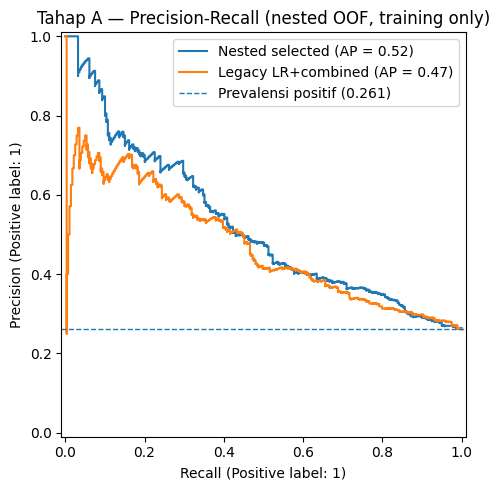

,selected_model,selected_ablation,jumlah_outer_fold
1,Logistic Regression,tfidf_only,9
0,Logistic Regression,non_digital_plus_tfidf,1


In [ ]:
fig,ax=plt.subplots(figsize=(7,5))
PrecisionRecallDisplay.from_predictions(y,ps,name='Nested selected',ax=ax)
PrecisionRecallDisplay.from_predictions(y,pb,name='Legacy LR+combined',ax=ax)
ax.axhline(y.mean(),linestyle='--',linewidth=1,label=f'Prevalensi positif ({y.mean():.3f})')
ax.legend();ax.set_title('Tahap A — Precision-Recall (nested OOF, training only)')
fig.tight_layout();fig.savefig(OUT_DIR/'07_precision_recall_nested.png',dpi=200,bbox_inches='tight');plt.show()
selection=(fold_df.groupby(['selected_model','selected_ablation']).size()
             .reset_index(name='jumlah_outer_fold').sort_values('jumlah_outer_fold',ascending=False))
selection.to_csv(OUT_DIR/'07_frekuensi_pemilihan_kandidat.csv',index=False)
display(selection)

## 12. Ekspor model Tahap A yang dipilih TANPA evaluasi ulang pada holdout

Pilihan *deployment candidate* dibuat dari semua data **training saja**: kandidat dipilih kembali melalui inner CV (mean AP), lalu threshold dihitung dengan inner OOF. Model dilatih pada 1.068 data training dan disimpan dengan `joblib`, siap diintegrasikan ke notebook DSS setelah keputusan metodologis. **Jangan mengganti angka holdout lama dengan evaluasi ulang pada 268 data yang sudah dilihat.**

In [ ]:
cv_final=StratifiedKFold(n_splits=INNER_FOLDS,shuffle=True,random_state=SEED+999)
full_rank=[]
for m,a in CANDIDATES:
    sc=cross_validate(stageA_estimator(m,a),Xa,ya,cv=cv_final,
         scoring={'ap':'average_precision','ba':'balanced_accuracy'},n_jobs=1,error_score='raise')
    full_rank.append((float(sc['test_ap'].mean()),float(sc['test_ba'].mean()),m,a))
final_row=sorted(full_rank,key=lambda x:(-x[0],-x[1],x[2],x[3]))[0]
selected_name,selected_ablation=final_row[2],final_row[3]
final_est=stageA_estimator(selected_name,selected_ablation)
p_oof_final=cross_val_predict(final_est,Xa,ya,cv=cv_final,method='predict_proba',n_jobs=1)[:,1]
final_threshold=choose_threshold(ya,p_oof_final)
final_est.fit(Xa,ya)
joblib.dump(final_est, OUT_DIR/'08_model_A_train_only.joblib',compress=3)
metadata={'model':selected_name,'ablation':selected_ablation,'threshold_train_oof':final_threshold,
          'data_train_count':len(Xa),'data_holdout_count_UNTOUCHED':len(test),
          'positive_proxy_train':int(ya.sum()),'model_score':'P(keanggotaan benchmark Maju+Mandiri sementara)',
          'selection':'3-fold inner CV mean average precision, tie by balanced accuracy',
          'threshold':'optimal F1 on out-of-fold train only',
          'status_label_JADESTA':'BELUM DIVERIFIKASI',
          'holdout_protocol':'Do NOT reuse previously inspected test to claim new unbiased performance',
          'uses_12_numeric_and_tfidf':selected_ablation=='structured_plus_tfidf',
          'feature_columns':TRAIN_INPUTS,
          'seed':SEED,'scikit_learn':sklearn_version}
(OUT_DIR/'08_model_A_metadata.json').write_text(json.dumps(metadata,indent=2,ensure_ascii=False))
print('Kandidat deployment:',selected_name,'+',selected_ablation,'| Threshold:',final_threshold)
print('Model merupakan STUDI AWAL benchmark proxy, bukan validasi resmi.')

Kandidat deployment: Logistic Regression + tfidf_only | Threshold: 0.4
Model merupakan STUDI AWAL benchmark proxy, bukan validasi resmi.


## 13. Ekspor paket hasil + instruksi integrasi DSS

Tabel CSV, grafik, file model, dan manifest diekspor ke satu ZIP. **Status Poin 2 reviewer:** dokumentasi robustness tersedia; keputusan final dan revisi manuskrip harus menunggu audit label resmi dan bila mungkin data evaluasi baru yang belum digunakan.

In [ ]:
report={
 'pipeline':'Stage A robustness on train only',
 'n_total':len(df),'n_train':len(train),'holdout_locked':len(test),
 'stageA_train_positive':int(ya.sum()),'stageA_train_negative':int((ya==0).sum()),
 'screening_models':MODELS_A,'ablations':list(ABLATIONS),
 'outer_folds':OUTER_FOLDS,'outer_repeats':OUTER_REPEATS,'inner_folds':INNER_FOLDS,
 'bootstrap_n':BOOTSTRAP_N,'fast_mode':FAST_MODE,'final_candidate':metadata,
 'limitation':'Proxy labels, missingness shift, previous holdout already inspected',
 'shap':'Tidak diulang: SHAP harus dijalankan setelah keputusan model A final bersama model B.'}
(OUT_DIR/'09_manifest_robustness.json').write_text(json.dumps(report,indent=2,ensure_ascii=False))
readme="\n".join([
 "HASIL AUDIT ROBUSTNESS TAHAP A — DSS Desa Wisata",
 "02_screening_12_kombinasi.csv : ablasi x 3 model (eksploratif, train only)",
 "03_nested_folds.csv : pemilihan model dan threshold INNER per outer fold",
 "03_nested_oof_predictions.csv : prediksi outer OOF; tidak menyentuh holdout lama",
 "04_nested_metrics_per_repeat.csv : evaluasi per repeat, bukan pengamatan independen",
 "05_bootstrap_95CI.csv : CI berpasangan tingkat desa atas repeat pertama",
 "06_group_holdout_kabupaten.csv : sensitivitas berdasarkan kabupaten/kota",
 "07_precision_recall_nested.png : kurva OOF train-only",
 "07_frekuensi_pemilihan_kandidat.csv : kestabilan kandidat terpilih",
 "08_model_A_train_only.joblib : calon model A (latih saja 1068 desa)",
 "08_model_A_metadata.json : threshold, fitur, konfigurasi",
 "Label di luar benchmark tidak sama dengan kelas resmi negatif JADESTA.",
 "DILARANG menggunakan ulang holdout yang sebelumnya sudah dilihat untuk mengklaim hasil baru independen.",
 "Hasil model A belum otomatis kompatibel dengan SHAP lama hingga model A+B DSS ditetapkan ulang."]) + "\n"
(OUT_DIR/'README.txt').write_text(readme)
output_zip=OUT_DIR.parent/'HASIL_ROBUSTNESS_TAHAP_A.zip'
with zipfile.ZipFile(output_zip,'w',zipfile.ZIP_DEFLATED) as z:
    for p in OUT_DIR.iterdir():
        if p.is_file():z.write(p,p.name)
print('Folder:',OUT_DIR.resolve())
print('ZIP:',output_zip.resolve())
try:
    from google.colab import files
    files.download(str(output_zip))
except ImportError: pass

Folder: /content/hasil_robustness_tahap_A
ZIP: /content/HASIL_ROBUSTNESS_TAHAP_A.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>